# **Quantenchaos und Scrambling**

Alexander Del Toro Barba, PhD

Das Notebook berechnet Out-of-Time-Order-Korrelatoren (OTOCs) in der Mixed-Field-Ising-Kette, exakt und für die integrable Kette zusätzlich mit freien Fermionen, misst die Schmetterlingsgeschwindigkeit in Haar-zufälligen Ziegelstein-Schaltkreisen gegen den exakten Wert 3/5, holt mit dem Hayden-Preskill-Protokoll (Yoshida-Kitaev-Dekoder in cirq) Information aus einem Modell eines Schwarzen Lochs zurück, berechnet die Page-Kurve von Zufallszuständen und nach einem Quench und vergleicht die Zeitskalen der Kette, vom Lichtkegel bis zur Heisenberg-Zeit und zur Poincaré-Wiederkehr.

Wie breitet sich eine lokale Störung in einem Quanten-Vielteilchensystem aus, und wie unterscheidet man echtes Scrambling von der Ausbreitung freier Quasiteilchen und von Dekohärenz?

#### **Hintergrund**

In der klassischen Mechanik heißt Chaos: Zwei benachbarte Bahnen entfernen sich exponentiell schnell voneinander, mit dem Lyapunov-Exponenten als Rate. Die Quantenmechanik hat keine Bahnen, und die unitäre Zeitentwicklung hält den Überlapp zweier Zustände konstant; diese Definition lässt sich also nicht übertragen. Quantenchaos zeigt sich stattdessen an drei anderen Stellen. Die erste ist, wie Operatoren unter der Zeitentwicklung wachsen, gemessen mit **Out-of-Time-Order-Korrelatoren** (OTOCs); Larkin und Ovchinnikov führten sie 1969 für Elektronen in Supraleitern ein, Kitaev (2015) sowie Maldacena, Shenker und Stanford (2016) machten sie zum Maß für Chaos. Die zweite ist die Statistik der Energieniveaus, die sich in chaotischen Systemen abstoßen wie die Eigenwerte von Zufallsmatrizen (Bohigas, Giannoni und Schmit 1984). Die dritte sind die Eigenzustände selbst, die für jede lokale Messung thermisch aussehen (Eigenzustands-Thermalisierung). **Scrambling** ist die dynamische Seite davon: Information, die anfangs in wenigen Qubits steckt, verteilt sich auf Korrelationen zwischen vielen. Dann lässt sie sich aus keinem kleinen Teil des Systems mehr ablesen, obwohl der Gesamtzustand rein bleibt und der Vorgang im Prinzip umkehrbar ist.

Scrambling erklärt, warum ein isoliertes Quantensystem thermalisiert, obwohl seine Zeitentwicklung unitär ist. Schwarze Löcher gelten als die schnellsten Scrambler der Natur, und die Frage, wie Information aus einem verdampfenden Schwarzen Loch herauskommt (Page-Kurve, Hayden-Preskill-Protokoll), ist eine der klarsten Stellen, an denen Quanteninformation auf Gravitation trifft. In Quantencomputern ist Scrambling zugleich Ressource und Hindernis: Zufallsschaltkreise, die scrambeln, erzeugen die schwer nachzurechnenden Verteilungen hinter den Experimenten zum Quantenvorteil; dieselbe Zufälligkeit lässt die Gradienten variationeller Schaltkreise verschwinden (Barren Plateaus); und OTOCs wurden mit NMR, gefangenen Ionen und supraleitenden Qubits gemessen, um zu prüfen, wie gut ein Gerät seine eigene Dynamik beherrscht.

Das Notebook verwendet exakte Simulationen kleiner Systeme (bis 12 Qubits) und ein exakt lösbares Modell (freie Fermionen, hier 24 Qubits). Es ist das erste Notebook einer Serie, die alle dieselbe Kette verwenden.

Landkarte:

- **Ausbreitung von Operatoren in einer Spinkette**
  - Lichtkegel in der Mixed-Field-Ising-Kette (Exp. 1): In der integrablen wie in der chaotischen Kette läuft die OTOC-Front ballistisch, fast mit der Geschwindigkeit des schnellsten Quasiteilchens. Hinter der Front relaxiert die integrable Kette, und die Front läuft zwischen den Enden hin und her; die chaotische Kette bleibt gescrambelt.
- **Schmetterlingsgeschwindigkeit**
  - Zufällige Ziegelstein-Schaltkreise (Exp. 2): Die gemessene Frontgeschwindigkeit von 0.595 Plätzen pro Schicht stimmt mit dem exakten $v_B = 3/5$ überein.
- **Information und Schwarze Löcher**
  - Hayden-Preskill (Exp. 3): Ein maximaler Scrambler gibt das Tagebuch aus einem einzigen Hawking-Qubit mit Fidelity 1 zurück; Rauschen senkt den OTOC genauso, holt aber nichts zurück.
  - Page-Kurve (Exp. 4): Ein Quench verschränkt in der chaotischen Kette die Hälfte fast so stark wie ein Zufallszustand (5.14 gegen 5.28 Bit); die integrable Kette bleibt bei etwa 2.8 Bit.
- **Zeitskalen**
  - Heisenberg-Zeit und Poincaré-Wiederkehr (Exp. 5): Die Heisenberg-Zeit wächst von 4.5 auf 1000 zwischen 1 und 12 Qubits; eine Rückkehr zum Anfangszustand dauert bei 3 Qubits 212 Zeiteinheiten, bei 4 Qubits 14 400 und ab 7 Qubits geschätzt länger als das Alter des Universums. Die integrable Kette kehrt viel öfter zurück.

Verwandte Notebooks: Niveauabstoßung und Zufallsmatrizen in [Zufallsmatrizen](https://github.com/deltorobarba/science/blob/main/maths/randommatrices.ipynb), klassisches Chaos und Lyapunov-Exponenten in [Dynamische Systeme und Chaos](https://github.com/deltorobarba/science/blob/main/maths/chaos.ipynb), Entropien und relative Entropie in [Quanteninformationstheorie und Abstandsmaße](https://github.com/deltorobarba/science/blob/main/quantum/quantuminformation.ipynb), eine Übersicht über Quantensimulation und Quantendynamik in den Notizen [Quantum Dynamics](https://github.com/deltorobarba/science/blob/main/quantum/quantumdynamics.md). Die weiteren Notebooks der Serie mit derselben Kette: [Spektralstatistik und Quantenchaos](https://github.com/deltorobarba/science/blob/main/quantum/chaos_spectra.ipynb), [Eigenzustands-Thermalisierung](https://github.com/deltorobarba/science/blob/main/quantum/chaos_eth.ipynb), [Krylov-Komplexität](https://github.com/deltorobarba/science/blob/main/quantum/chaos_krylov.ipynb) und [Vielteilchenlokalisierung](https://github.com/deltorobarba/science/blob/main/quantum/chaos_mbl.ipynb).

#### **Theorie**

##### *1. Operatorwachstum im Heisenberg-Bild*

Im **Heisenberg-Bild** bleiben die Zustände fest, und die Operatoren entwickeln sich, $W(t) = e^{iHt}\,W\,e^{-iHt}$ (mit $\hbar = 1$). Die Entwicklung in verschachtelte Kommutatoren,
$$W(t) = W + it\,[H, W] - \frac{t^2}{2}\,[H, [H, W]] + \dots ,$$
zeigt, wie ein Operator wächst: Bei einem lokalen Hamiltonoperator kann jeder Kommutator den Träger des Operators um einen Platz vergrößern. In der Basis der **Pauli-Strings**, der Tensorprodukte aus $I$, $X$, $Y$ und $Z$ auf allen Qubits, wird ein Operator auf einem Platz wie $Z_0$ zu einer Überlagerung immer längerer Strings. **Scrambling** heißt, dass sich das Gewicht auf exponentiell viele Strings verteilt, sodass man den Operator mit lokalen Messungen nicht mehr erkennt.

Drei Fragen beschreiben dieses Wachstum:
- **Rate:** Wie schnell wächst er in der Zeit? (Quanten-Lyapunov-Exponent, Abschnitt 4)
- **Reichweite:** Wie schnell wächst sein Träger im Raum? (Schmetterlingsgeschwindigkeit, Abschnitt 5)
- **Tiefe:** Wie komplex wird er im Raum der Operatoren? (Krylov-Komplexität, Abschnitt 6)

OTOCs und Operatorwachstum sind **dynamische Diagnosen**: Sie brauchen die Zeitentwicklung $e^{-iHt}$. Spektralstatistik und Eigenzustands-Thermalisierung (Abschnitt 8) sind **statische Diagnosen**, die nur Eigenwerte und Eigenvektoren von $H$ verwenden.

##### *2. Die Mixed-Field-Ising-Kette*

Das Modell der Experimente 1, 3, 4 und 5 ist eine Kette aus $N$ Qubits mit offenen Enden,
$$H = J\sum_{i=0}^{N-2} Z_iZ_{i+1} + h_x\sum_{i=0}^{N-1} X_i + h_z\sum_{i=0}^{N-1} Z_i ,$$
mit $J = h_x = 1$. Die Zeit wird in Einheiten von $1/J$ gemessen.

**Integrabel bei $h_z = 0$** (Ising-Kette im Querfeld). Die **Jordan-Wigner-Transformation** bildet die Spins auf **Majorana-Fermionen** ab,
$$\gamma_{2k} = \Big(\prod_{l<k}X_l\Big)Z_k, \qquad \gamma_{2k+1} = \Big(\prod_{l<k}X_l\Big)Y_k, \qquad \lbrace\gamma_a, \gamma_b\rbrace = 2\delta_{ab} .$$
Dann ist $X_k = i\gamma_{2k}\gamma_{2k+1}$ und $Z_kZ_{k+1} = i\gamma_{2k+1}\gamma_{2k+2}$: Der Hamiltonoperator ist quadratisch in den Fermionen, $H = \tfrac i4\sum_{ab}A_{ab}\gamma_a\gamma_b$ mit einer reellen antisymmetrischen $2N\times2N$-Matrix $A$. Ein quadratischer Hamiltonoperator beschreibt **freie Fermionen**: Jeder Majorana-Operator entwickelt sich linear, $\gamma_a(t) = \sum_b [e^{At}]_{ab}\,\gamma_b$, und die Dynamik von $N$ Qubits braucht eine $2N\times2N$-Matrix statt einer $2^N\times2^N$-Matrix. Die Anregungen sind **Quasiteilchen** mit der Energie $\varepsilon_k = 2\sqrt{J^2 + h_x^2 - 2Jh_x\cos k}$ und der Gruppengeschwindigkeit $v_k = d\varepsilon_k/dk$, höchstens
$$v_\text{max} = 2\min(J, h_x) ,$$
hier also 2 Plätze pro Zeiteinheit. Sie bewegen sich ballistisch, streuen nie und werden an den offenen Enden reflektiert.

**Chaotisch bei $h_z \neq 0$** (hier $h_z = 0.5$). Unter Jordan-Wigner wird $Z_k$ zu einem String aus Fermion-Operatoren; das Längsfeld ist also nicht quadratisch, die Quasiteilchen streuen, und die Kette verhält sich wie ein typisches chaotisches System. Kim und Huse (2013) nahmen fast dieselben Parameter (Feldstärken 1.05 und 0.5) als Standardbeispiel einer nicht integrablen Kette.

**Der OTOC der freien Kette.** Mit dem Schmetterling $V = X_0 = i\gamma_0\gamma_1$ und der Sonde $W_j = Z_j$, einem String der Majoranas $\gamma_0, \dots, \gamma_{2j}$, lässt sich der OTOC aus Abschnitt 3 exakt berechnen. Konjugation mit $Z_j$ lässt die Majoranas im String unverändert und dreht bei allen anderen das Vorzeichen um: $Z_j\gamma_aZ_j = s_a\gamma_a$ mit $s_a = +1$ für $a \le 2j$ und $s_a = -1$ sonst. Mit $V(-t) = i(u\cdot\gamma)(w\cdot\gamma)$, wobei $u$ und $w$ die ersten beiden Zeilen von $e^{-At}$ sind, und $D = \mathrm{diag}(s)$ lässt der Satz von Wick für die Spur von vier Majoranas eine $2\times2$-Determinante übrig:
$$F_j(t) = (u\cdot Du)(w\cdot Dw) - (u\cdot Dw)^2 .$$
Der Aufwand wächst wie $N^3$ statt wie $8^N$.

##### *3. Der Out-of-Time-Order-Korrelator*

Zwei Operatoren auf weit entfernten Plätzen vertauschen bei $t = 0$. Der **quadrierte Kommutator**
$$\mathcal C(t) = \big\langle [W(t), V]^\dagger\,[W(t), V] \big\rangle$$
misst, wie weit $W(t)$ in den Platz von $V$ hineingewachsen ist. Für unitäre und hermitesche Operatoren wie Pauli-Operatoren ist er gleich $2\big(1 - \mathrm{Re}\,F(t)\big)$ mit dem **Out-of-Time-Order-Korrelator**
$$F(t) = \big\langle W(t)^\dagger\, V^\dagger\, W(t)\, V \big\rangle .$$
Das Notebook mittelt über alle Zustände, $\langle\cdot\rangle = 2^{-N}\,\mathrm{Tr}(\cdot)$ (unendliche Temperatur), und zeigt den halben quadrierten Kommutator, $C_j(t) = 1 - \mathrm{Re}\,F_j(t)$ für die Sonde auf Qubit $j$:
- $C = 0$: $W(t)$ und $V$ vertauschen noch, die Störung ist noch nicht angekommen;
- $C = 1$ ($F = 0$): der Wert eines vollständig gescrambelten Operators, der in der Hälfte seiner Pauli-Strings mit $V$ vertauscht und in der anderen Hälfte antivertauscht;
- $C$ bis 2: $W(t)$ antivertauscht mit $V$, wie $Z_0$ und $X_0$ bei $t = 0$.

**Warum „out of time order“:** In $F(t)$ laufen die Zeiten $t \to 0 \to t \to 0$. Einen solchen Korrelator kann man nicht als gewöhnlichen zeitgeordneten Erwartungswert schreiben, dessen Zeitweg nur einmal vorwärts läuft. Gewöhnliche Zweipunktfunktionen wie $\langle W(t)W\rangle$ zerfallen schon in der lokalen Thermalisierungszeit und sehen die spätere Ausbreitung von Korrelationen über viele Qubits nicht; der OTOC verfolgt sie.

**Messung als Echo** (Loschmidt-Echo): vorwärts entwickeln mit $e^{-iHt}$, den Schmetterling $V$ anwenden, rückwärts entwickeln mit $e^{+iHt}$ (auf Hardware durch Umkehren des Vorzeichens von $H$) und den Überlapp mit der Sonde $W$ messen. Alles, was mit $V$ vertauscht, hebt sich zwischen Vorwärts- und Rückwärtsentwicklung auf; nur der nicht vertauschende Teil bleibt übrig.

##### *4. Rate: der Quanten-Lyapunov-Exponent*

In Systemen mit vielen Freiheitsgraden $N$ pro Platz und in semiklassischen Systemen wächst der quadrierte Kommutator zunächst exponentiell, $\mathcal C(t) \sim \frac1N e^{\lambda_Lt}$, mit dem **Quanten-Lyapunov-Exponenten** $\lambda_L$. Im semiklassischen Grenzfall wird der Kommutator zur Poisson-Klammer, $-\langle[x(t), p]^2\rangle \to \hbar^2\,\lbrace x(t), p\rbrace^2 \sim \hbar^2e^{2\lambda_\text{cl}t}$, weil $\lbrace x(t), p(0)\rbrace = \partial x(t)/\partial x(0)$ misst, wie stark eine kleine Änderung des Anfangsorts anwächst. Das verbindet $\lambda_L$ mit dem klassischen Lyapunov-Exponenten.

Die Zeitskalen sind geordnet: die **lokale Thermalisierungszeit** $t_\text{therm} \sim \mathcal O(1)$, nach der lokale Größen relaxiert sind; die **Scrambling-Zeit** $t_\ast \sim \lambda_L^{-1}\ln N$, nach der der Kommutator überall von der Größe 1 ist; und die **Heisenberg-Zeit** $t_H \sim e^{S}$, der Kehrwert des Niveauabstands, nach der sich die Diskretheit des Spektrums zeigt (mit der Entropie $S$). Eine **Poincaré-Wiederkehr**, eine fast vollständige Rückkehr zum Anfangszustand, dauert noch viel länger (Abschnitt 13).

In Spin-1/2-Ketten mit kurzreichweitiger Wechselwirkung gibt es keinen großen Parameter $N$ pro Platz; der exponentielle Bereich ist kurz oder fehlt, und die Geschwindigkeit der Front (Abschnitt 5) ist die Größe, die man zuverlässig messen kann.

##### *5. Reichweite: Schmetterlingsgeschwindigkeit und Lieb-Robinson-Schranke*

Weit weg vom Schmetterling bleibt der quadrierte Kommutator klein, bis eine Front ankommt. Sie läuft mit der **Schmetterlingsgeschwindigkeit** $v_B$; in Systemen mit großem $N$ ist $\mathcal C(t, x) \sim \frac1N\exp[\lambda_L(t - x/v_B)]$.

Die **Lieb-Robinson-Schranke** gilt für jeden Hamiltonoperator mit lokaler Wechselwirkung: $\Vert[A(t), B]\Vert \le c\,e^{-\mu(d - v_\text{LR}t)}$ für Operatoren $A$ und $B$ im Abstand $d$. Außerhalb des Lichtkegels $d > v_\text{LR}t$ ist jeder Kommutator exponentiell klein. $v_\text{LR}$ ist eine Eigenschaft von $H$ allein (eine Schranke für Operatornormen), $v_B$ hängt dagegen vom Zustand und von der Temperatur ab, und $v_B \le v_\text{LR}$. In der Kette freier Fermionen läuft die Front mit dem schnellsten Quasiteilchen, $v_\text{max}$.

**Zufallsschaltkreise.** In einem Ziegelstein-Schaltkreis aus Haar-zufälligen Zwei-Qudit-Gattern mit lokaler Dimension $q$ ist der über Schaltkreise gemittelte OTOC exakt lösbar: Das rechte Ende des wachsenden Operators macht eine Zufallsbewegung mit Vorwärtstendenz. Daraus folgt
$$v_B = \frac{q^2 - 1}{q^2 + 1} \qquad (= 3/5 \text{ für Qubits}),$$
in Einheiten, in denen der strenge Lichtkegel einen Platz pro Schicht vorrückt, und eine Front, deren Breite wie $\sqrt t$ wächst (Nahum, Vijay und Haah 2018; von Keyserlingk, Rakovszky, Pollmann und Sondhi 2018).

**Verschränkung und Schaltkreistiefe.** Nach einem Quench wächst die Verschränkungsentropie der halben Kette linear, $S(t) \approx v_E\,t$, mit einer **Verschränkungsgeschwindigkeit** $v_E \le v_B$ (Mezei und Stanford 2017). Ihre Schwankungen in einer Dimension und die Schwankungen der OTOC-Front in zwei Dimensionen gehören zur Kardar-Parisi-Zhang-Universalitätsklasse (KPZ), mit einer Breite, die wie $t^{1/3}$ wächst. Weil Information das ganze Gerät durchqueren muss, braucht die Verschränkung aller $n$ Qubits eine Tiefe der Größe $n$ in einer Dimension, $\sqrt n$ in zwei Dimensionen und $\log n$ bei Verbindungen zwischen allen Qubits.

##### *6. Tiefe: Krylov-Komplexität*

Wiederholte Kommutatoren mit $H$ spannen den **Krylov-Raum** $\mathcal K = \mathrm{span}\lbrace W, [H, W], [H, [H, W]], \dots\rbrace$ auf. Der Lanczos-Algorithmus baut darin eine Orthonormalbasis $O_0, O_1, \dots$, in der der Liouville-Operator $\mathcal L = [H, \cdot\,]$ tridiagonal ist, mit den **Lanczos-Koeffizienten** $b_n$ als Sprungamplituden. Der Operator wird zu einer Welle auf einer halbunendlichen Kette, $W(t) = \sum_n i^n\varphi_n(t)\,O_n$, und die **Krylov-Komplexität**
$$K(t) = \sum_n n\,\vert\varphi_n(t)\vert^2$$
ist ihre mittlere Position. Das Wachstum der $b_n$ bestimmt das Wachstum von $K$: Konstante $b_n$ geben $K \propto t$, $b_n \propto \sqrt n$ gibt $K \propto t^2$, und lineares Wachstum $b_n \approx \alpha n$ gibt $K \sim e^{2\alpha t}$. Die **Hypothese des universellen Operatorwachstums** (Parker et al. 2019) besagt, dass die $b_n$ in chaotischen Systemen so schnell wie möglich wachsen, linear (in einer Dimension mit logarithmischer Korrektur). Die Wachstumsrate begrenzt den Lyapunov-Exponenten, $\lambda_L \le 2\alpha$. Ausführlich in [Krylov-Komplexität](https://github.com/deltorobarba/science/blob/main/quantum/chaos_krylov.ipynb).

##### *7. Schranken und das SYK-Modell*

Bei der Temperatur $T = 1/\beta$ begrenzt die **Schranke von Maldacena, Shenker und Stanford** (MSS) das Chaos:
$$\lambda_L \le \frac{2\pi k_BT}{\hbar} = \frac{2\pi}{\beta} .$$
Sie folgt aus der Analytizität thermischer Korrelatoren im Streifen $0 \le \mathrm{Im}\,t \le \beta$ (der **KMS-Bedingung**). Parker et al. argumentieren, dass dieselbe Analytizität das Lanczos-Wachstum auf $\alpha \le \pi/\beta$ begrenzt, was zusammen mit $\lambda_L \le 2\alpha$ wieder die MSS-Schranke ergibt.

Das **Sachdev-Ye-Kitaev-Modell** (SYK) besteht aus $N$ Majorana-Fermionen mit zufälligen Vierteilchen-Wechselwirkungen zwischen allen. Es ist für großes $N$ exakt lösbar, bei tiefer Temperatur dual zu einer zweidimensionalen Gravitationstheorie (Jackiw-Teitelboim-Gravitation in $\mathrm{AdS}_2$) und erreicht die Schranke, $\lambda_L = 2\pi/\beta$. Schwarze Löcher erreichen sie ebenfalls; ihre Scrambling-Zeit $t_\ast \sim \frac{\beta}{2\pi}\ln S$ ist die kürzest mögliche, und Sekino und Susskind (2008) vermuteten, dass Schwarze Löcher die schnellsten Scrambler der Natur sind.

##### *8. Statische Signaturen: Spektralstatistik und Eigenzustands-Thermalisierung*

**Niveaustatistik.** Nach der Vermutung von Bohigas, Giannoni und Schmit haben die Energieniveaus eines chaotischen Quantensystems die Statistik einer Zufallsmatrix: Benachbarte Niveaus stoßen sich ab (**Wigner-Dyson**-Statistik). Integrable Systeme haben unkorrelierte Niveaus (**Poisson**-Statistik, Berry und Tabor). Ein bequemer Test ist das Verhältnis aufeinanderfolgender Abstände $s_n$, $r_n = \min(s_n, s_{n+1})/\max(s_n, s_{n+1})$, mit dem Mittelwert $\langle r\rangle \approx 0.53$ für reelle symmetrische Zufallsmatrizen (GOE) und $\approx 0.39$ für Poisson. Es braucht kein Umskalieren des Spektrums, aber die Niveaus verschiedener Symmetriesektoren müssen vorher getrennt werden (die offene Ising-Kette hat eine Spiegelsymmetrie). Ausführlich in [Spektralstatistik und Quantenchaos](https://github.com/deltorobarba/science/blob/main/quantum/chaos_spectra.ipynb).

**Spektraler Formfaktor.** $K(t) = \langle\vert\mathrm{Tr}\,e^{-iHt}\vert^2\rangle$, gemittelt über ein Ensemble von Hamiltonoperatoren, hat die typische Form **Abfall, Rampe, Plateau**: ein schneller Abfall, eine lineare Rampe durch die Niveauabstoßung und ein Plateau nach der Heisenberg-Zeit. Die Rampe zeigt Korrelationen zwischen Niveaus noch lange, nachdem die OTOCs gesättigt sind.

**Hypothese der Eigenzustands-Thermalisierung (ETH).** In einem chaotischen System haben die Matrixelemente einer lokalen Observablen in der Energie-Eigenbasis die Form
$$A_{mn} = \mathcal A(\bar E)\,\delta_{mn} + e^{-S(\bar E)/2}\,f_A(\bar E, \omega)\,R_{mn} ,$$
mit einer glatten Funktion $\mathcal A$ der mittleren Energie $\bar E$, der Entropie $S$, einer glatten Funktion $f_A$ von $\bar E$ und $\omega = E_m - E_n$ und Zufallszahlen $R_{mn}$. Ein einzelner Eigenzustand sieht dann für jede lokale Observable thermisch aus. Integrable Systeme haben viele zusätzliche Erhaltungsgrößen (in der freien Kette die Besetzung jeder Quasiteilchen-Mode) und relaxieren auf ein **verallgemeinertes Gibbs-Ensemble** (GGE) statt auf einen thermischen Zustand. In **vielteilchenlokalisierten** Systemen verhindern lokale Erhaltungsgrößen die Thermalisierung ganz. Ausführlich in [Eigenzustands-Thermalisierung](https://github.com/deltorobarba/science/blob/main/quantum/chaos_eth.ipynb) und [Vielteilchenlokalisierung](https://github.com/deltorobarba/science/blob/main/quantum/chaos_mbl.ipynb).

##### *9. Scrambling gegen Dekohärenz*

Beide lassen den OTOC zerfallen, aus verschiedenen Gründen:
- **Unitäres Scrambling:** Die Information verteilt sich umkehrbar auf Vielteilchen-Verschränkung und ließe sich im Prinzip aus dem ganzen System zurückgewinnen. Die Entropie kleiner Teilsysteme steigt, der Gesamtzustand bleibt rein. $F(t) \to 0$, weil der Operator wächst.
- **Dekohärenz** (ein offenes System, etwa beschrieben durch eine Lindblad-Gleichung): Die Information fließt unumkehrbar in eine Umgebung ab. Die Entropie des ganzen Systems wächst. $F(t) \to 0$, weil die Kohärenzen gedämpft werden.

Ein zerfallender OTOC allein kann also durch Rauschen vorgetäuscht werden, das einen falschen Lyapunov-Exponenten erzeugt. Yoshida und Yao (2019) zeigten, dass die Fidelity des Hayden-Preskill-Dekoders (Abschnitt 10) die beiden trennt: Sie steigt nur bei echtem Scrambling.

##### *10. Schwarze Löcher: Hayden-Preskill und die Page-Kurve*

**Hayden-Preskill.** Ein altes Schwarzes Loch nach seiner Page-Zeit ist maximal mit der Hawking-Strahlung verschränkt, die es schon abgegeben hat. Alice wirft ein Tagebuch aus $k$ Qubits hinein. Hayden und Preskill (2007) zeigten: Sobald das Schwarze Loch das Tagebuch gescrambelt hat, kann Bob, der die frühe Strahlung besitzt, es aus nur wenig mehr als $k$ neu abgestrahlten Hawking-Qubits zurückgewinnen. Das Schwarze Loch wirkt wie ein Informationsspiegel. **Yoshida-Kitaev-Dekoder:** Bob wendet $U^\ast$ auf seine Kopie der frühen Strahlung zusammen mit einer Hälfte eines frischen EPR-Paars $(A', R')$ an und projiziert dann das Hawking-Qubit $D$ und seinen Partner $D'$ auf ein EPR-Paar. Für unitäres $U$ gilt:
- Die Erfolgswahrscheinlichkeit $P_\text{EPR}$ ist der über alle Pauli-Operatoren auf $A$ und $D$ gemittelte OTOC;
- die Fidelity des Ergebnisses mit einem EPR-Paar ist $F_\text{EPR} = 1/(d_A^2\,P_\text{EPR})$, mit der Dimension $d_A$ des Tagebuchs;
- ein perfekter Scrambler gibt $P = 1/d_A^2$ und $F = 1$; ohne Scrambling ist $P = 1$ und $F = 1/d_A^2$.

**Page-Kurve.** Page (1993) berechnete die mittlere Verschränkungsentropie eines Teilsystems der Dimension $m \le k$ in einem Haar-zufälligen reinen Zustand auf $mk$ Dimensionen:
$$S = \sum_{j=k+1}^{mk}\frac1j - \frac{m-1}{2k} \approx \ln m - \frac{m}{2k} .$$
Man lese die ersten $l$ von $N$ Qubits als Strahlung und den Rest als Schwarzes Loch. Die Entropie der Strahlung steigt dann um etwa ein Bit pro abgestrahltem Qubit bis zur **Page-Zeit** $l = N/2$ und fällt danach: die **Page-Kurve**. Damit das Verdampfen unitär ist, muss nach der Page-Zeit Information herauskommen. Bei $l = N/2$ bleibt die Entropie $1/(2\ln2) \approx 0.72$ Bit unter dem Maximum von $N/2$ Bit.

##### *11. Scrambling in Quantencomputern*

- **Barren Plateaus:** Tiefe Zufallsschaltkreise kommen unitären **2-Designs** nahe, Ensembles, die die ersten beiden Momente des Haar-Maßes wiedergeben. Das Mitteln über das Haar-Maß gibt dann exponentiell kleine Gradienten, $\mathrm{Var}_\theta[\partial_\theta\langle H\rangle] \sim 2^{-n}$ (McClean et al. 2018); zufällig gestartete variationelle Schaltkreise lassen sich nicht trainieren.
- **Random Circuit Sampling:** Die Ausgabewahrscheinlichkeiten $p$ eines scrambelnden Schaltkreises auf $n$ Qubits folgen der **Porter-Thomas-Verteilung** $P(p) \approx \mathcal N e^{-\mathcal Np}$ mit $\mathcal N = 2^n$. Boixo et al. (2018) schätzten, dass sich die Verteilung Porter-Thomas annähert, sobald Information das Gerät durchquert hat, bei einer Tiefe der Größe $\sqrt n$ in zwei Dimensionen. Die schwächere Eigenschaft der **Antikonzentration**, auf die sich Härte-Argumente stützen, setzt schon bei einer Tiefe der Größe $\log n$ ein (Dalzell, Hunter-Jones und Brandão 2022).

##### *12. Ausbreitung, Diffusion und Scrambling*

Nach einer lokalen Störung passieren drei verschiedene Dinge, und man verwechselt sie leicht.

**Ballistische Ausbreitung der Front.** „Ballistisch“ heißt: Die Front läuft mit konstanter Geschwindigkeit, wie ein geworfener Ball; ihre Position wächst wie $x_\text{Front}(t) = vt$. Doppelte Zeit heißt doppelter Weg. Die Lieb-Robinson-Schranke (Abschnitt 5) erlaubt höchstens das. In beiden Ketten von Experiment 1 läuft die OTOC-Front ballistisch (1.83 und 1.70 Plätze pro Zeiteinheit), ebenso die Front in den Zufallsschaltkreisen von Experiment 2 ($v_B = 3/5$).

**Diffusion.** „Diffusiv“ heißt: Ein Abstand wächst nur wie $\sqrt t$, wie bei einer Zufallsbewegung, in der jeder Schritt zufällig vor- oder zurückgeht. Für den doppelten Weg braucht man die vierfache Zeit, wie bei Tinte in Wasser oder Wärme in einem Stab. In einer chaotischen Kette tritt Diffusion an zwei Stellen auf, aber nicht in der Bewegung der Front:
- Die **Breite der Front** wächst wie $\sqrt t$, weil das Ende des Operators eine Zufallsbewegung mit Vorwärtstendenz macht (exakt für Zufallsschaltkreise, Abschnitt 5; zu sehen rechts in Experiment 2). In der Kette freier Fermionen wird der Rand der Front von den schnellsten Quasiteilchen gebildet, die wie eine Airy-Funktion interferieren, und er wird langsamer breiter, etwa wie $t^{1/3}$.
- **Erhaltungsgrößen** wie die Energie werden durch lokale Stöße weitergegeben und breiten sich diffusiv aus, $\langle x^2\rangle \propto t$. Kim und Huse (2013) zeigten für fast diese Kette, dass die Energie diffundiert, während sich Verschränkung und Operatoren ballistisch ausbreiten; ihr Artikel heißt „ballistische Ausbreitung von Verschränkung in einem diffusiven nicht integrablen System“. In einer integrablen Kette tragen Quasiteilchen die Erhaltungsgrößen, und auch sie bewegen sich ballistisch.

**Scrambling** betrifft nicht die Front, sondern das, was hinter ihr passiert: Der Operator wird zu einer Überlagerung exponentiell vieler Pauli-Strings mit scheinbar zufälligen Koeffizienten, der OTOC mit jeder Sonde sättigt beim gescrambelten Wert und bleibt dort, und die Information lässt sich aus keinem kleinen Teil des Systems mehr ablesen (Hayden-Preskill, Abschnitt 10).

Die integrable Kette **breitet sich also aus, scrambelt aber nicht**. $X_0$ bleibt eine Bilinearform aus Fermionen, ein Operator in einem Raum mit nur $N(2N - 1)$ Dimensionen statt $4^N$ (in [Krylov-Komplexität](https://github.com/deltorobarba/science/blob/main/quantum/chaos_krylov.ipynb) hat die Krylov-Kette der integrablen Kette bei 6 Qubits 61 Glieder, die der chaotischen 4036). Die Information reist mit den Quasiteilchen und ist dort wiederzufinden, wo sie gerade sind: Hinter der Front fällt $C$ wieder gegen 0, die Front kommt nach jeder Reflexion zurück, und die Dekodier-Fidelity aus Experiment 3 fällt wieder ab („Unscrambling“). Ein wachsender OTOC allein heißt also nur Ausbreitung (operator spreading); Scrambling braucht zusätzlich die Sättigung hinter der Front.

| | integrabel ($h_z = 0$) | chaotisch ($h_z = 0.5$) |
|---|---|---|
| Bewegung der OTOC-Front | ballistisch, $v \le v_\text{max} = 2$ | ballistisch, $v_B \approx 1.7$ |
| Breite der Front | wächst langsam (Airy-Rand) | wächst wie $\sqrt t$ (Zufallsbewegung) |
| Transport der Energie | ballistisch (Quasiteilchen) | diffusiv |
| hinter der Front | $C$ fällt gegen 0, Fronten kommen zurück | $C$ sättigt nahe 1 |
| Scrambling | nein | ja |

##### *13. Zeitskalen: Heisenberg-Zeit und Poincaré-Wiederkehr*

Ein Zustand $\vert\psi(0)\rangle = \sum_nc_n\vert n\rangle$ entwickelt sich wie $\vert\psi(t)\rangle = \sum_nc_ne^{-iE_nt}\vert n\rangle$. Alles, was passiert, ist das Zusammenspiel der Phasen $E_nt$. Seine **Rückkehrwahrscheinlichkeit** ist
$$P(t) = \vert\langle\psi(0)\vert\psi(t)\rangle\vert^2 = \Big\vert\sum_np_n\,e^{-iE_nt}\Big\vert^2, \qquad p_n = \vert c_n\vert^2 .$$
Sie zerfällt in der Zeit $1/\sigma_E$, die die Energiebreite $\sigma_E$ des Zustands festlegt, und schwankt dann um ihr Zeitmittel $\sum_np_n^2 = 1/D_\text{eff}$, wobei $D_\text{eff}$ die Zahl der Niveaus ist, die wirklich beteiligt sind.

**Heisenberg-Zeit.** Die Niveaus eines endlichen Systems sind diskret, mit dem mittleren Abstand $\Delta$. Ein Vorgang der Dauer $t$ löst Energien nur auf etwa $2\pi\hbar/t$ genau auf (Energie-Zeit-Unschärfe); die Dynamik merkt die Diskretheit also erst nach der **Heisenberg-Zeit**
$$t_H = \frac{2\pi\hbar}{\Delta} .$$
Bei $N$ Qubits liegen $2^N$ Niveaus in einem Band, das nur wie $N$ breiter wird; also ist $\Delta \propto N2^{-N}$ und $t_H \propto 2^N/N \sim e^{S}$. Für eine ungefähr gaußförmige Zustandsdichte gibt der Abstand in ihrer Mitte $t_H \approx \sqrt{2\pi}\,n/\sigma$, mit $n$ Niveaus der Standardabweichung $\sigma$. Vor $t_H$ verhält sich das System, als wäre sein Spektrum kontinuierlich: Relaxation, OTOC-Wachstum, Scrambling und Thermalisierung passieren alle hier. Bei $t_H$ erreicht der spektrale Formfaktor sein Plateau ([Spektralstatistik und Quantenchaos](https://github.com/deltorobarba/science/blob/main/quantum/chaos_spectra.ipynb), Experiment 4), und die Schwankungen von Observablen um das Gleichgewicht mitteln sich nicht weiter heraus. $t_H$ ist in kleinen Quantensimulatoren erreichbar (hier 80 bei 8 Qubits, 1000 bei 12), wächst aber exponentiell mit der Größe.

**Poincaré-Wiederkehr.** Poincaré (1890) bewies, dass ein beschränktes klassisches System beliebig nahe an seinen Anfangszustand zurückkehrt. Bocchieri und Loinger (1957) zeigten dasselbe für ein Quantensystem mit diskretem Spektrum: $\vert\psi(t)\rangle$ ist quasiperiodisch, und $P(t)$ kommt wieder beliebig nahe an 1, aber nur, wenn alle Phasen $E_nt$ gleichzeitig nahe an Vielfachen von $2\pi$ liegen. Das ist ungefähr so unwahrscheinlich, wie wenn $D$ Würfel gleichzeitig dieselbe Zahl zeigen sollen. Haben die Energien keine rationalen Verhältnisse, durchlaufen die Phasen mit der Zeit alle Kombinationen gleichmäßig, wie unabhängige Zufallszahlen. Nahe einer Rückkehr ist $P \approx 1 - \varphi^TM\varphi$ für die relativen Phasen $\varphi$, mit $\det M = \prod_np_n$; der Zeitanteil mit $P > 1 - \varepsilon$ ist also das Volumen eines kleinen Ellipsoids in $D - 1$ Dimensionen,
$$f \approx \frac{V_{D-1}\,\varepsilon^{(D-1)/2}}{(2\pi)^{D-1}\sqrt{\prod_np_n}}, \qquad V_k = \frac{\pi^{k/2}}{\Gamma(k/2 + 1)} .$$
Nach dem **Lemma von Kac** ist die mittlere Zeit zwischen zwei Rückkehren die Verweildauer pro Besuch, etwa $2\sqrt\varepsilon/\sigma_E$, geteilt durch $f$. Sie wächst wie $\varepsilon^{-D/2}$: exponentiell in der Zahl der Niveaus $D \sim 2^N$, also doppelt exponentiell in $N$, $t_P \sim e^{e^S}$.

**Wann zählt welche Zeitskala?**
- Poincaré-Wiederkehr zählt bei **Systemen mit wenigen Niveaus**: Ein Qubit in einem Feld kehrt bei jeder Periode exakt zurück (Rabi-Oszillation); ein Atom im Resonator zeigt Kollaps und Wiederaufleben (Jaynes-Cummings-Modell); Wellenpakete von Rydberg-Atomen leben wieder auf; ein harmonischer Oszillator, dessen Niveaus gleich weit auseinander liegen, kehrt exakt zurück.
- In **integrablen oder freien Systemen** sind die Energien Summen aus nur $N$ Quasiteilchen-Energien; es müssen also nur $N$ Phasen zusammenpassen, und die Wiederkehr kommt exponentiell in $N$, nicht doppelt exponentiell (Experiment 5).
- Die zurückkehrenden Fronten aus Experiment 1 (die W-Form) sind weder das eine noch das andere: Es sind Hin- und Rückwege von Quasiteilchen, $2(N - 1)/v_\text{max}$, linear in $N$.
- In **chaotischen Vielteilchensystemen** spielt Poincaré-Wiederkehr praktisch nie eine Rolle; die Heisenberg-Zeit ist die längste Zeitskala mit physikalischen Folgen.

Die ganze Reihenfolge für eine Kette aus $N$ Qubits: lokale Relaxation $\sim 1 \;<\;$ Front durchquert die Kette $\sim N/v_B \;<\;$ Heisenberg-Zeit $\sim e^{S} \;<\;$ Poincaré-Wiederkehr $\sim e^{e^S}$.

#### **Code**

Die Werkzeuge, die mehrere Experimente brauchen: die Pauli-Matrizen, `site_op` für einen Operator auf einem Qubit der Kette und der Hamiltonoperator der Mixed-Field-Ising-Kette aus Theorie, Abschnitt 2, als dichte Matrix. `H_X = 1` und `H_Z = 0.5` sind die Felder in allen Experimenten ($J = 1$). Die erste Zelle installiert `cirq`, Googles Bibliothek für Quantenschaltkreise, mit der Experiment 3 den Hayden-Preskill-Schaltkreis baut und simuliert.

In [1]:
# Colab: cirq installieren (Googles Bibliothek für Quantenschaltkreise). Lokal wird nichts automatisch installiert,
# weil pip numpy und andere Pakete einer conda-Umgebung verändern kann; dort cirq selbst installieren,
# am besten mit conda (conda-forge).
import importlib.util, subprocess, sys
if "google.colab" in sys.modules:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "cirq"], check=True)
elif importlib.util.find_spec("cirq") is None:
    raise ImportError("Es fehlt cirq; bitte lokal selbst installieren, am besten mit conda (conda-forge), "
                      "damit numpy unverändert bleibt")

In [2]:
import cirq                      # https://quantumai.google/cirq
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import eigh, expm
from scipy.signal import find_peaks
from scipy.stats import unitary_group

X = np.array([[0, 1], [1, 0]], dtype=complex)
Z = np.array([[1, 0], [0, -1]], dtype=complex)

def site_op(op, j, n):
    """Ein-Qubit-Operator `op` auf Qubit j einer Kette aus n Qubits (Qubit 0 = linker Tensorfaktor)."""
    mats = [np.eye(2, dtype=complex)] * n
    mats[j] = op
    out = mats[0]
    for m in mats[1:]:
        out = np.kron(out, m)
    return out

def ising_hamiltonian(n, h_x, h_z, J=1.0):
    """Mixed-Field-Ising-Kette H = J Σ Z_i Z_{i+1} + h_x Σ X_i + h_z Σ Z_i mit offenen Enden (Theorie, Abschnitt 2).
    h_z = 0: integrabel (freie Fermionen), h_z != 0: chaotisch."""
    H = sum(J * site_op(Z, i, n) @ site_op(Z, i + 1, n) for i in range(n - 1))
    return H + sum(h_x * site_op(X, i, n) + h_z * site_op(Z, i, n) for i in range(n))

H_X, H_Z = 1.0, 0.5              # Feldstärken in allen Experimenten (J = 1)
print("Werkzeuge bereit: Pauli-Matrizen, Operatoren auf einzelnen Qubits, Mixed-Field-Ising-Hamiltonoperator")

Werkzeuge bereit: Pauli-Matrizen, Operatoren auf einzelnen Qubits, Mixed-Field-Ising-Hamiltonoperator


#### **Experimente**

##### *1. Der Lichtkegel in der Ising-Kette*

Wie breitet sich der OTOC zwischen einem Schmetterling $X_0$ am linken Ende der Kette und einer Sonde $Z_j$ entlang der Kette aus, und was passiert hinter der Front in der integrablen und in der chaotischen Kette? Vorher vorhersagen: Welche der beiden Ketten breitet sich schneller aus, und in welcher fällt $C$ nach dem Durchgang der Front wieder gegen 0?

Die Zelle berechnet $C_j(t) = 1 - F_j(t)$ (Theorie, Abschnitt 3) für $N = 8$ Qubits aus der exakten Zeitentwicklung $U(t) = e^{-iHt}$, gewonnen aus der Eigenzerlegung des $256\times256$-Hamiltonoperators, für $t$ von 0 bis 30 in Schritten von 0.1. Der Schmetterling ist $V = X_0$, die Sonden sind $W_j = Z_j$ auf jedem Qubit. Oben stehen die integrable ($h_z = 0$) und die chaotische Kette ($h_z = 0.5$) mit der Linie $x = v_\text{max}t$ des schnellsten Quasiteilchens. Unten links steht das ferne Ende $j = 7$ über der Zeit. Unten rechts steht die integrable Kette mit 24 Qubits, berechnet mit der Formel für freie Fermionen aus Theorie, Abschnitt 2, die die Zelle vorher an der exakten Rechnung mit 8 Qubits prüft. Eine exakte Rechnung im $2^{24}$-dimensionalen Raum wäre unerreichbar; die mit freien Fermionen dauert weniger als eine Sekunde.

**Hintergrund & Fachbegriffe:**
- **Schmetterling und Sonde:** $V = X_0$ ist die lokale Störung, der „Schmetterling“; $W_j = Z_j$ ist der Operator, der prüft, ob die Störung bei Qubit $j$ angekommen ist.
- **Exakte Diagonalisierung:** $H = S\,\mathrm{diag}(E)\,S^\dagger$ gibt $e^{-iHt} = S\,\mathrm{diag}(e^{-iEt})\,S^\dagger$ exakt für jedes $t$; mit dichten Matrizen geht das bis etwa 14 Qubits.
- **Lichtkegel und Front:** der Bereich in der $(t, j)$-Ebene, in dem $C$ von 0 abweicht, und sein Rand.
- **Ballistische Ausbreitung:** Die Front läuft mit konstanter Geschwindigkeit, ihre Position wächst wie $t$ (diffusive Ausbreitung wüchse wie $\sqrt t$; Theorie, Abschnitt 12).
- **Offene Enden:** Die Kette endet bei den Qubits 0 und $N - 1$; ein Signal, das an einem Ende ankommt, wird reflektiert.

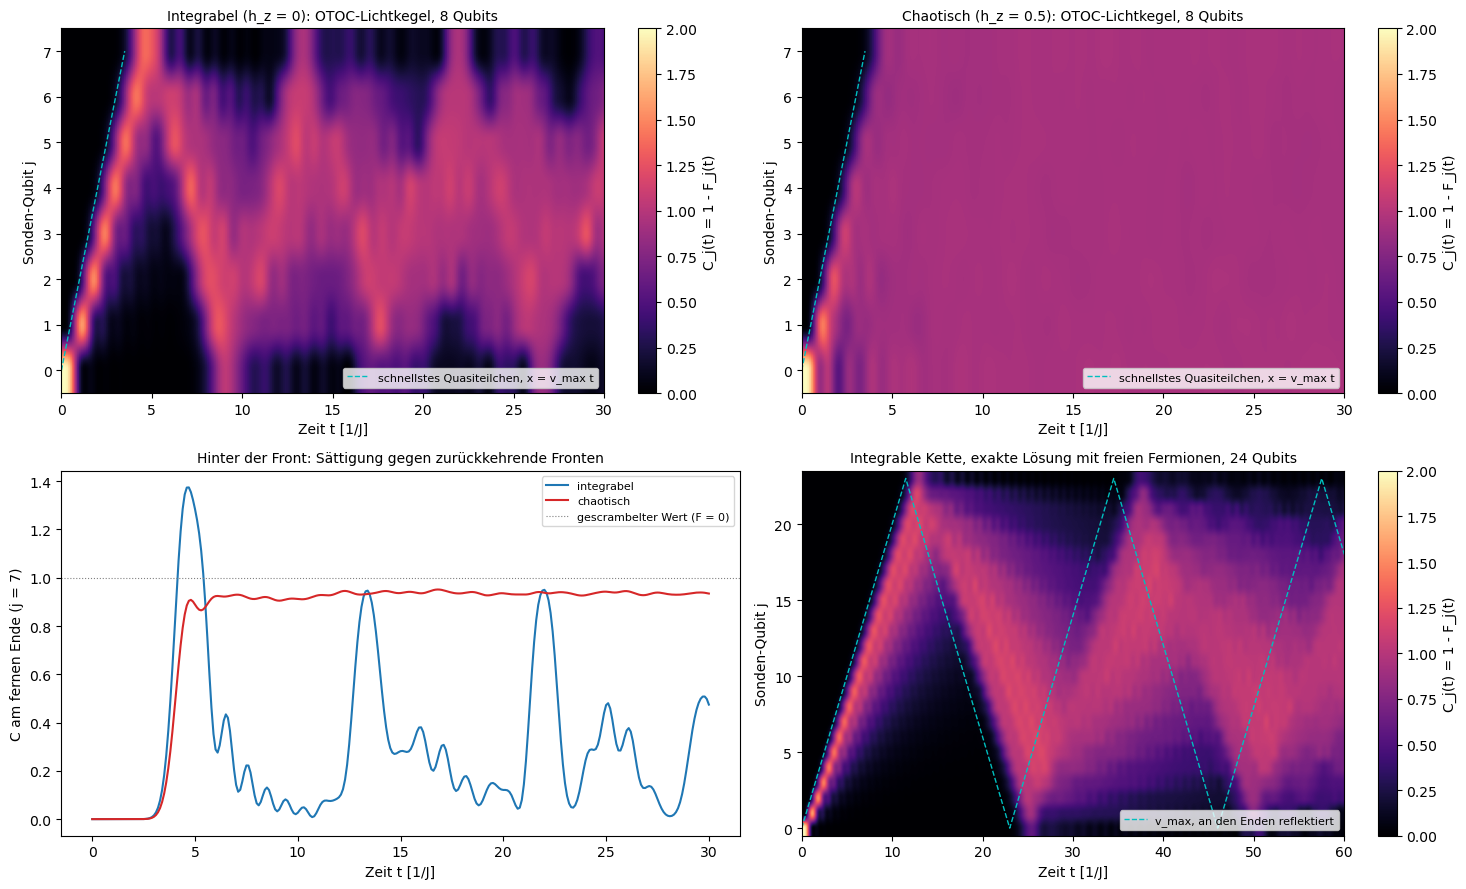

Freie Fermionen gegen exakte Diagonalisierung (8 Qubits): größte Abweichung 3.0e-13
integrabel: Front erreicht j = 1 ... 7 bei t = [0.6 1.2 1.8 2.3 2.8 3.4 3.9]:  Geschwindigkeit 1.83 Plätze pro 1/J (v_max = 2)
chaotisch : Front erreicht j = 1 ... 7 bei t = [0.6 1.2 1.8 2.4 3.  3.6 4.1]:  Geschwindigkeit 1.70 Plätze pro 1/J (v_max = 2)
Spätes Mittel von C (t > 15) am fernen Ende:  integrabel 0.27  |  chaotisch 0.94
Integrable Kette: Die Front kehrt bei t = [ 4.7 13.4 22. ] zum fernen Ende zurück


In [3]:
def otoc_light_cone(n, h_x, h_z, times):
    """C_j(t) = 1 - F_j(t),  F_j(t) = Tr[W_j(t) V W_j(t) V] / 2^n,  Schmetterling V = X_0, Sonde W_j = Z_j.
    Exakte Zeitentwicklung U(t) = exp(-iHt) aus der Eigenzerlegung von H."""
    E, S = eigh(ising_hamiltonian(n, h_x, h_z))
    V = site_op(X, 0, n)
    Ws = [site_op(Z, j, n) for j in range(n)]
    C = np.zeros((n, len(times)))
    for k, t in enumerate(times):
        U = (S * np.exp(-1j * E * t)) @ S.conj().T
        for j, W in enumerate(Ws):
            W_t = U.conj().T @ W @ U                                     # Heisenberg-Bild
            C[j, k] = 1 - np.trace(W_t @ V @ W_t @ V).real / 2 ** n
    return C

def otoc_free_fermions(n, h_x, times, J=1.0):
    """Derselbe OTOC für die integrable Kette (h_z = 0) aus freien Majorana-Fermionen (Theorie, Abschnitt 2); Aufwand ~ n^3.
    gamma(t) = exp(At) gamma,  X_0 = i gamma_0 gamma_1,  Z_j = String der Majoranas 0, ..., 2j."""
    A = np.zeros((2 * n, 2 * n))
    A[np.arange(0, 2 * n, 2), np.arange(1, 2 * n, 2)] = 2 * h_x        # h_x X_k     = h_x (i/2)·2 gamma_2k gamma_2k+1
    A[np.arange(1, 2 * n - 2, 2), np.arange(2, 2 * n - 1, 2)] = 2 * J  # J Z_k Z_k+1 = J (i/2)·2 gamma_2k+1 gamma_2k+2
    A = A - A.T
    C = np.zeros((n, len(times)))
    for k, t in enumerate(times):
        u, w = expm(-A * t)[:2]                                        # V(-t) = i (u·gamma)(w·gamma)
        for j in range(n):
            s = np.where(np.arange(2 * n) <= 2 * j, 1.0, -1.0)         # Z_j gamma_a Z_j = s_a gamma_a
            C[j, k] = 1 - ((u @ (s * u)) * (w @ (s * w)) - (u @ (s * w)) ** 2)
    return C

# --- Ausführung ---
N_QUBITS, T_MAX = 8, 30.0                    # exakte Diagonalisierung: 2^8 = 256 Zustände
times = np.linspace(0, T_MAX, 301)
C_int = otoc_light_cone(N_QUBITS, H_X, 0.0, times)
C_chaos = otoc_light_cone(N_QUBITS, H_X, H_Z, times)
C_check = otoc_free_fermions(N_QUBITS, H_X, times)          # muss mit C_int übereinstimmen
N_FF, T_FF = 24, 60.0                        # freie Fermionen: eine längere Kette kostet fast nichts
times_ff = np.linspace(0, T_FF, 1201)
C_ff = otoc_free_fermions(N_FF, H_X, times_ff)
V_MAX = 2 * min(1.0, H_X)                    # schnellstes Quasiteilchen der integrablen Kette, v_max = 2 min(J, h_x)

def bouncing_ray(t, n):
    """Position eines Signals, das bei Platz 0 startet, mit v_max läuft und an beiden offenen Enden reflektiert wird."""
    phase = (V_MAX * t) % (2 * (n - 1))
    return np.where(phase <= n - 1, phase, 2 * (n - 1) - phase)

fig, axes = plt.subplots(2, 2, figsize=(15, 9))
t_first = np.linspace(0, (N_QUBITS - 1) / V_MAX, 50)
for ax, C, title in [(axes[0, 0], C_int, "Integrabel (h_z = 0)"), (axes[0, 1], C_chaos, f"Chaotisch (h_z = {H_Z})")]:
    im = ax.imshow(C, aspect="auto", origin="lower", cmap="magma", vmin=0, vmax=2,
                   extent=[times[0], times[-1], -0.5, N_QUBITS - 0.5])
    ax.plot(t_first, V_MAX * t_first, "c--", lw=1, label="schnellstes Quasiteilchen, x = v_max t")
    ax.set_title(f"{title}: OTOC-Lichtkegel, {N_QUBITS} Qubits", fontsize=10)
    ax.set_xlabel("Zeit t [1/J]")
    ax.set_ylabel("Sonden-Qubit j")
    ax.legend(fontsize=8, loc="lower right")
    fig.colorbar(im, ax=ax, label="C_j(t) = 1 - F_j(t)")
far = N_QUBITS - 1
axes[1, 0].plot(times, C_int[far], label="integrabel", c="tab:blue")
axes[1, 0].plot(times, C_chaos[far], label="chaotisch", c="tab:red")
axes[1, 0].axhline(1, color="grey", ls=":", lw=0.8, label="gescrambelter Wert (F = 0)")
axes[1, 0].set_xlabel("Zeit t [1/J]")
axes[1, 0].set_ylabel(f"C am fernen Ende (j = {far})")
axes[1, 0].set_title("Hinter der Front: Sättigung gegen zurückkehrende Fronten", fontsize=10)
axes[1, 0].legend(fontsize=8)
im = axes[1, 1].imshow(C_ff, aspect="auto", origin="lower", cmap="magma", vmin=0, vmax=2,
                       extent=[times_ff[0], times_ff[-1], -0.5, N_FF - 0.5])
axes[1, 1].plot(times_ff, bouncing_ray(times_ff, N_FF), "c--", lw=1, label="v_max, an den Enden reflektiert")
axes[1, 1].set_xlim(times_ff[0], times_ff[-1])
axes[1, 1].set_title(f"Integrable Kette, exakte Lösung mit freien Fermionen, {N_FF} Qubits", fontsize=10)
axes[1, 1].set_xlabel("Zeit t [1/J]")
axes[1, 1].set_ylabel("Sonden-Qubit j")
axes[1, 1].legend(fontsize=8, loc="lower right")
fig.colorbar(im, ax=axes[1, 1], label="C_j(t) = 1 - F_j(t)")
plt.tight_layout()
plt.show()

def front_speed(C):
    """Ankunftszeit = erste Zeit mit C_j >= 1/2; die Steigung von j gegen sie (j = 1 ... n-1) ist die Frontgeschwindigkeit."""
    arrival = np.array([times[np.argmax(C[j] >= 0.5)] for j in range(1, C.shape[0])])
    return np.polyfit(arrival, np.arange(1, C.shape[0]), 1)[0], arrival
late = times > T_MAX / 2
peaks, _ = find_peaks(C_int[far], height=0.7)
print(f"Freie Fermionen gegen exakte Diagonalisierung ({N_QUBITS} Qubits): größte Abweichung {np.abs(C_check - C_int).max():.1e}")
for label, C in [("integrabel", C_int), ("chaotisch", C_chaos)]:
    v, arrival = front_speed(C)
    print(f"{label:10s}: Front erreicht j = 1 ... {far} bei t = {np.round(arrival, 2)}:  Geschwindigkeit {v:.2f} Plätze pro 1/J (v_max = {V_MAX:.0f})")
print(f"Spätes Mittel von C (t > {T_MAX / 2:.0f}) am fernen Ende:  integrabel {C_int[far, late].mean():.2f}  |  chaotisch {C_chaos[far, late].mean():.2f}")
print(f"Integrable Kette: Die Front kehrt bei t = {np.round(times[peaks], 1)} zum fernen Ende zurück")

* Die **obere Reihe** zeigt $C_j(t)$ als Farbe, mit dem Sonden-Qubit $j$ nach oben und der Zeit nach rechts. In beiden Ketten beginnt der helle Bereich beim Schmetterling ($C = 2$ bei $j = 0$, $t = 0$, weil $X_0$ und $Z_0$ antivertauschen) und läuft entlang einer Geraden nach oben: Die Front ist **in beiden Phasen ballistisch** und kommt knapp hinter der gestrichelten Linie des schnellsten Quasiteilchens an, $x = v_\text{max}t$ mit $v_\text{max} = 2$. Hinter der Front unterscheiden sich die Ketten. In der integrablen laufen helle Streifen zum fernen Ende, werden reflektiert und kommen zurück, mit dunklen Bereichen dazwischen: das Zickzack- oder W-Muster. Die chaotische Kette wird gleichmäßig bei $C \approx 0.9$ bis 1 und bleibt dort.
* Das **Bild unten links** zeigt das ferne Ende $j = 7$. In der integrablen Kette erreicht $C$ bei $t = 4.7$ ein Maximum von 1.37 ($F < 0$) und fällt wieder gegen 0; es kommt bei $t = 13.4$ und $t = 22.0$ zurück, jedes Mal, wenn die reflektierte Front wieder am Ende ankommt. Die chaotische Kette steigt auf etwa 0.9 und bleibt dort: Der Operator ist gescrambelt und entscrambelt sich nicht. Das **Bild unten rechts** zeigt die integrable Kette mit 24 Qubits: Die Front durchquert die Kette, wird am fernen Ende reflektiert, kommt zurück und wird wieder reflektiert. Ihr vorderer Rand folgt dem gestrichelten Strahl des schnellsten Quasiteilchens, das für Hin- und Rückweg $2(N - 1)/v_\text{max} = 23$ Zeiteinheiten braucht; der hellste Teil ist etwas langsamer und fällt nach jeder Reflexion weiter zurück. Das W-Muster ist also die Reflexion freier Quasiteilchen an den offenen Enden, keine Poincaré-Wiederkehr, die unvorstellbar viel länger dauern würde (Theorie, Abschnitt 13, und Experiment 5).
* Die **Ausgabe** bestätigt, dass die Formel für freie Fermionen bis auf $3\cdot10^{-13}$ mit der exakten Diagonalisierung übereinstimmt. Die Front erreicht das ferne Ende bei $t = 3.9$ (integrabel) und $4.1$ (chaotisch); nach den Durchgängen durch die halbe Höhe läuft sie mit 1.83 und 1.70 Plätzen pro Zeiteinheit, beide unter $v_\text{max} = 2$. Nach $t = 15$ ist das Mittel am fernen Ende $C = 0.27$ in der integrablen und $0.94$ in der chaotischen Kette.

##### *2. Schmetterlingsgeschwindigkeit in Zufallsschaltkreisen*

Wie schnell breitet sich ein Operator in einem Schaltkreis aus zufälligen Zwei-Qubit-Gattern aus, und stimmt die gemessene Geschwindigkeit mit dem exakten $v_B = 3/5$ überein? Vorher vorhersagen: Der strenge Lichtkegel rückt einen Platz pro Schicht vor. Ist die OTOC-Front genauso schnell, schneller oder langsamer, und warum?

Die Zelle simuliert 12 Qubits, 20 Zufallsschaltkreise und 16 Schichten. Der Schmetterling ist $V = Z_0$, durch den Schaltkreis entwickelt, die Sonden sind $W_j = Z_j$. Statt der normierten Spur über alle $2^{12}$ Zustände verwendet sie einen einzigen Haar-zufälligen Zustand (Typizität). Die Front ist die Stelle, an der das über Schaltkreise gemittelte $C_j(t)$ den Wert 1/2 kreuzt, und eine Gerade durch die Schichten 3 bis 16, ohne die Punkte am rechten Rand, gibt $v_B$ (Theorie, Abschnitt 5).

**Hintergrund & Fachbegriffe:**
- **Haar-zufälliges Gatter:** eine unitäre Matrix aus der Gleichverteilung auf der Gruppe $U(4)$ (dem Haar-Maß). Ein solches Gatter hat keine Struktur und erhält nichts.
- **Ziegelstein-Schaltkreis:** Schichten aus Zwei-Qubit-Gattern auf den Bindungen $(0,1), (2,3), \dots$ im Wechsel mit $(1,2), (3,4), \dots$; der strenge Lichtkegel wächst um einen Platz pro Schicht.
- **Typizität:** Für einen Zufallszustand $\vert\psi\rangle$ stimmt $\langle\psi\vert O\vert\psi\rangle$ bis auf einen Fehler der Größe $2^{-N/2}$ mit der normierten Spur $2^{-N}\mathrm{Tr}\,O$ überein, hier etwa 1.5 %.
- **Schaltkreis-Mittel:** der über viele Zufallsschaltkreise gemittelte OTOC; dieses Mittel beschreibt die exakte Theorie.

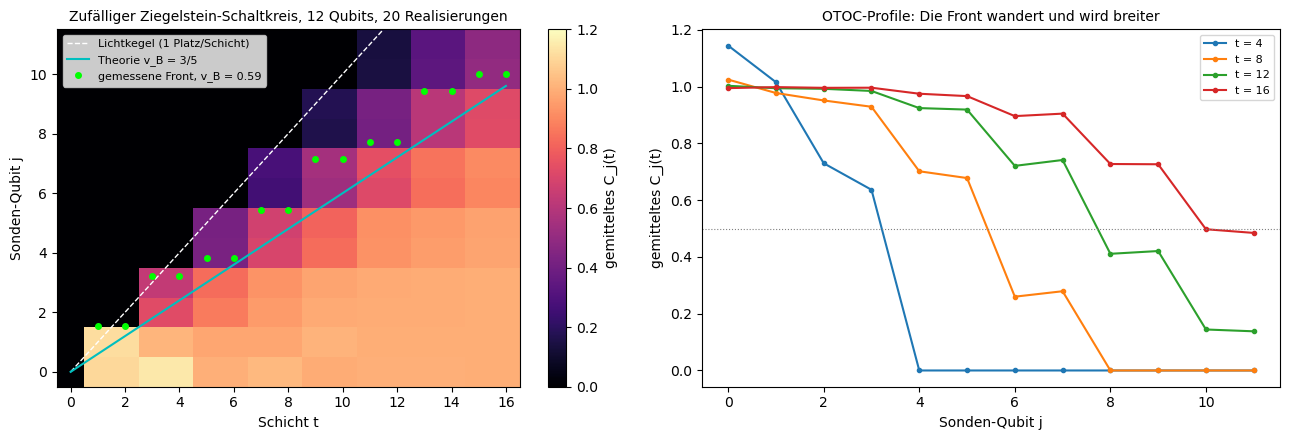

Schmetterlingsgeschwindigkeit (Gerade durch die Schichten 3-16)
  Gemessen:  v_B = 0.595 Plätze/Schicht
  Theorie:   v_B = (q² - 1)/(q² + 1) = 0.600   (q = 2, Haar-zufällige Gatter)
  Lichtkegel:     1 Platz/Schicht   ->  Information breitet sich mit 60% der größten Geschwindigkeit aus


In [4]:
def apply_2q(psi, gate, i, n):
    """Ein 4x4-Gatter auf die Qubits (i, i+1) eines Zustandsvektors aus n Qubits anwenden."""
    psi = psi.reshape([2] * n)
    psi = np.moveaxis(psi, [i, i + 1], [0, 1]).reshape(4, -1)
    psi = (gate @ psi).reshape([2, 2] + [2] * (n - 2))
    return np.moveaxis(psi, [0, 1], [i, i + 1]).reshape(-1)

def apply_1q(psi, op, j, n):
    psi = np.moveaxis(psi.reshape([2] * n), j, 0)
    psi = np.tensordot(op, psi, axes=1)
    return np.moveaxis(psi, 0, j).reshape(-1)

def brickwork(n, depth, rng):
    """Zufallsschaltkreis: Schicht t setzt Haar-zufällige Zwei-Qubit-Gatter auf die Bindungen (i, i+1) mit i = t mod 2, t mod 2 + 2, ..."""
    return [[(i, unitary_group.rvs(4, random_state=rng)) for i in range(t % 2, n - 1, 2)] for t in range(depth)]

def evolve(psi, layers, n, dagger=False):
    """U|psi> (oder U^dagger|psi>) für den Schaltkreis U = L_T ... L_1."""
    seq = reversed(layers) if dagger else layers
    for layer in seq:
        for i, g in layer:
            psi = apply_2q(psi, g.conj().T if dagger else g, i, n)
    return psi

def otoc_profile(n, layers, psi):
    """C_j = 1 - Re <psi| V(t) W_j V(t) W_j |psi>,  V = Z_0 (Schmetterling, entwickelt), W_j = Z_j (Sonde).
    Ein einziger Haar-zufälliger Zustand |psi> ersetzt die normierte Spur (Typizität, Fehler ~ 2^(-n/2))."""
    C = np.zeros(n)
    for j in range(n):
        phi = apply_1q(psi, Z, j, n)                                   # W_j
        for step in range(2):                                          # zweimal (V(t) W_j)
            phi = evolve(phi, layers, n)                               # U
            phi = apply_1q(phi, Z, 0, n)                               # V
            phi = evolve(phi, layers, n, dagger=True)                  # U^dagger  -> V(t)
            if step == 0:
                phi = apply_1q(phi, Z, j, n)                           # W_j
        C[j] = 1 - np.vdot(psi, phi).real
    return C

# --- Ausführung ---
N_RC       = 12     # Qubits (Zustandsvektor 2^12 = 4096)
DEPTH      = 16     # Schichten; der strenge Lichtkegel rückt 1 Platz pro Schicht vor
N_CIRCUITS = 20     # Zahl der Zufallsschaltkreise für das Mittel
rng = np.random.default_rng(1)

C_rc = np.zeros((N_CIRCUITS, DEPTH + 1, N_RC))
for r in range(N_CIRCUITS):
    circuit = brickwork(N_RC, DEPTH, rng)
    psi0 = rng.normal(size=2 ** N_RC) + 1j * rng.normal(size=2 ** N_RC)   # Haar-zufälliger Zustand
    psi0 /= np.linalg.norm(psi0)
    for t in range(1, DEPTH + 1):
        C_rc[r, t] = otoc_profile(N_RC, circuit[:t], psi0)
C_mean = C_rc.mean(axis=0)                                             # Mittel über die Schaltkreise

# Position der Front: wo der gemittelte OTOC die Hälfte seines gescrambelten Werts C = 1 kreuzt
x_front = np.array([np.interp(0.5, C_mean[t][::-1], np.arange(N_RC)[::-1]) if C_mean[t].max() > 0.5 else np.nan
                    for t in range(DEPTH + 1)])
fit = (np.arange(DEPTH + 1) >= 3) & (x_front < N_RC - 2)              # Anfang und rechten Rand auslassen
v_fit, x0 = np.polyfit(np.arange(DEPTH + 1)[fit], x_front[fit], 1)
V_THEORY = (2 ** 2 - 1) / (2 ** 2 + 1)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
im = axes[0].imshow(C_mean.T, aspect="auto", origin="lower", cmap="magma", vmin=0, vmax=1.2,
                    extent=[-0.5, DEPTH + 0.5, -0.5, N_RC - 0.5])
tt = np.linspace(0, DEPTH, 100)
axes[0].plot(tt, tt, "w--", lw=1, label="Lichtkegel (1 Platz/Schicht)")
axes[0].plot(tt, V_THEORY * tt, "c-", lw=1.5, label=f"Theorie v_B = 3/5")
axes[0].plot(np.arange(DEPTH + 1), x_front, "o", c="lime", ms=4, label=f"gemessene Front, v_B = {v_fit:.2f}")
axes[0].set_ylim(-0.5, N_RC - 0.5)
axes[0].set_xlabel("Schicht t")
axes[0].set_ylabel("Sonden-Qubit j")
axes[0].set_title(f"Zufälliger Ziegelstein-Schaltkreis, {N_RC} Qubits, {N_CIRCUITS} Realisierungen", fontsize=10)
axes[0].legend(fontsize=8, loc="upper left")
fig.colorbar(im, ax=axes[0], label="gemitteltes C_j(t)")
for t in [4, 8, 12, 16]:
    if t <= DEPTH:
        axes[1].plot(np.arange(N_RC), C_mean[t], "o-", ms=3, label=f"t = {t}")
axes[1].axhline(0.5, color="grey", ls=":", lw=0.8)
axes[1].set_xlabel("Sonden-Qubit j")
axes[1].set_ylabel("gemitteltes C_j(t)")
axes[1].set_title("OTOC-Profile: Die Front wandert und wird breiter", fontsize=10)
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

print(f"Schmetterlingsgeschwindigkeit (Gerade durch die Schichten {np.arange(DEPTH + 1)[fit].min()}-{np.arange(DEPTH + 1)[fit].max()})")
print(f"  Gemessen:  v_B = {v_fit:.3f} Plätze/Schicht")
print(f"  Theorie:   v_B = (q² - 1)/(q² + 1) = {V_THEORY:.3f}   (q = 2, Haar-zufällige Gatter)")
print(f"  Lichtkegel:     1 Platz/Schicht   ->  Information breitet sich mit {V_THEORY:.0%} der größten Geschwindigkeit aus")

* Das **linke Bild** zeigt das gemittelte $C_j(t)$ gegen die Schicht $t$ (waagrecht) und das Sonden-Qubit $j$. Die weiße gestrichelte Linie ist der strenge Lichtkegel (1 Platz pro Schicht), die türkise Linie die Theorie $v_B = 3/5$, die grünen Punkte die gemessene Front, die der türkisen Linie in Stufen von zwei Plätzen folgt, weil jedes Gatter zwei Qubits umfasst. Hinter der Front nähert sich $C$ dem gescrambelten Wert 1, wie in der chaotischen Kette von Experiment 1.
* Das **rechte Bild** zeigt die Profile nach 4, 8, 12 und 16 Schichten: nahe 1 hinter der Front, abfallend auf 0 davor. Die Front wandert nach rechts und wird mit der Zeit breiter (die $\sqrt t$-Verbreiterung der Zufallsbewegung, Theorie, Abschnitt 12). Werte knapp über 1 nahe dem Schmetterling bei $t = 4$ kommen von Pauli-Strings mit einem $X$ oder $Y$ auf Qubit 0, die mit $Z_0$ antivertauschen und dort noch mehr als die Hälfte des Gewichts tragen.
* Die **Ausgabe** gibt $v_B = 0.595$ Plätze pro Schicht gegen exakt $0.600$: Information breitet sich mit 60 % der größten Geschwindigkeit aus, die der Schaltkreis erlaubt. Mit 14 Qubits, 20 Schaltkreisen und 20 Schichten ergibt die Gerade 0.594 (etwa 1.5 Minuten, Variation 4).

##### *3. Schwarze Löcher: Information mit dem Hayden-Preskill-Protokoll zurückholen*

Kann Bob Alices Tagebuch aus einem einzigen Hawking-Qubit zurückgewinnen, und kann sein Dekoder Scrambling von Dekohärenz unterscheiden? Vorher vorhersagen: Welche Fidelity erreicht Bob, wenn das Schwarze Loch gar nicht scrambelt, und welche, wenn es nur dekohäriert?

Die Zelle simuliert den Yoshida-Kitaev-Dekoder aus Theorie, Abschnitt 10, mit 8 Qubits in cirq. Das Tagebuch ist ein Qubit ($d_A = 2$), das Schwarze Loch hat zwei weitere Qubits, und ein ausdrückliches Referenz-Qubit $R$ macht die Fidelity $F_\text{EPR}$ direkt berechenbar:

| Qubit | R | A | B1 B2 | B1′ B2′ | A′ | R′ |
|---|---|---|---|---|---|---|
| Rolle | Referenz | Tagebuch | Schwarzes Loch (B2 = Hawking-Qubit D) | frühe Strahlung (Bob) | EPR-Hälfte des Dekoders | Ergebnis |

Verglichen werden vier Scrambler $U$ auf den drei Qubits des Schwarzen Lochs: die Zeitentwicklung der Ising-Kette mit 3 Qubits (chaotisch und integrabel) für $t$ von 0 bis 6, 40 Haar-zufällige unitäre Matrizen und ein Clifford-Schaltkreis, der maximal scrambelt (durch numerische Suche gefunden). Ein fünfter Fall scrambelt gar nicht ($U = 1$), hat aber depolarisierendes Rauschen im Schwarzen Loch.

**Hintergrund & Fachbegriffe:**
- **EPR-Paar:** der Bell-Zustand $(\vert00\rangle + \vert11\rangle)/\sqrt2$ zweier maximal verschränkter Qubits.
- **Bell-Messung:** eine Messung, die fragt, ob zwei Qubits in diesem EPR-Zustand sind; hier als Projektion auf die Dichtematrix berechnet, die Erfolgswahrscheinlichkeit ist $P_\text{EPR}$.
- **Teleportations-Fidelity $F_\text{EPR}$:** der Überlapp des Endzustands von $(R, R')$ mit einem EPR-Paar. $F = 1$ heißt, das Tagebuch ist perfekt bei $R'$ angekommen; $F = 1/4$ erreicht man durch Raten.
- **Clifford-Schaltkreis:** ein Schaltkreis aus H-, CNOT- und CZ-Gattern; er bildet jeden Pauli-String auf einen anderen Pauli-String ab und lässt sich klassisch effizient simulieren.
- **Depolarisierendes Rauschen:** Mit Wahrscheinlichkeit $p$ erleidet das Qubit einen $X$-, $Y$- oder $Z$-Fehler (je mit $p/3$).
- **Dichtematrix-Simulator:** simuliert gemischte Zustände $\rho$ statt Zustandsvektoren, was Rauschen braucht.

Hayden-Preskill-Schaltkreis mit dem maximalen Scrambler:
          ┌──┐
0: ───H────@─────────────
           │
1: ────────X─────U[1]────
                 │
2: ───H────@─────U[2]────
           │     │
3: ───H────┼@────U[3]────
           ││
4: ────────X┼────U*[2]───
            │    │
5: ─────────X────U*[3]───
                 │
6: ───H────@─────U*[1]───
           │
7: ────────X─────────────
          └──┘


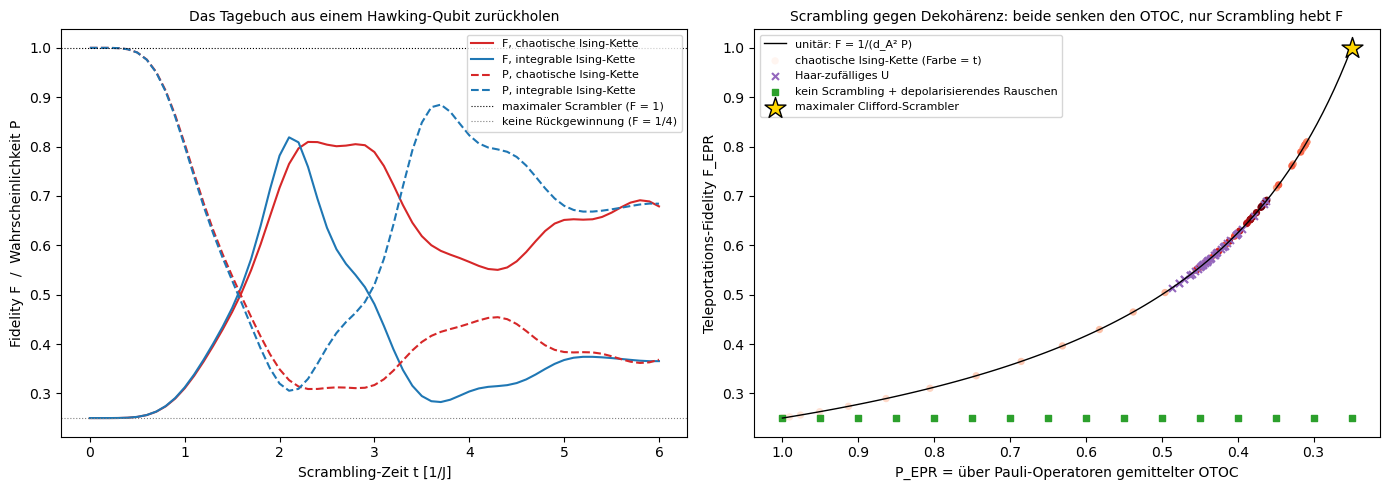

Yoshida-Kitaev-Dekoder (d_A = 2)
  Maximaler Scrambler:          P = 0.250, F = 1.000   (Theorie: P = 1/d_A² = 0.25, F = 1)
  Haar-zufälliges U (40 Stück): F = 0.580 ± 0.041
  Chaotische Ising-Kette:       bestes F = 0.809 bei t = 2.3
  Integrable Ising-Kette:       bestes F = 0.819 bei t = 2.1, danach kleinstes F = 0.282
  Depolarisierendes Rauschen p = 0.75: P = 0.250 (OTOC zerfällt), F = 0.250 (keine Rückgewinnung)
  Prüfung F·d_A²·P = 1 für alle unitären U: größte Abweichung 3.3e-15


In [5]:
# Qubits: R (Referenz) - A (Alices Tagebuch) - B1 B2 (Schwarzes Loch) | B1' B2' (frühe Strahlung, bei Bob) - A' R' (Bobs Dekoder-Paar)
R, A, B1, B2, B1p, B2p, Ap, Rp = cirq.LineQubit.range(8)
QUBITS = [R, A, B1, B2, B1p, B2p, Ap, Rp]

def bell_pair(a, b):
    return [cirq.H(a), cirq.CNOT(a, b)]

def bell_projector(a, b):
    """|Φ+><Φ+| auf den Qubits (a, b) = (II + XX - YY + ZZ)/4, als 256x256-Matrix auf allen 8 Qubits."""
    ps = (cirq.PauliString() + cirq.X(a) * cirq.X(b) - cirq.Y(a) * cirq.Y(b) + cirq.Z(a) * cirq.Z(b)) / 4
    return ps.matrix(QUBITS)

def hayden_preskill_circuit(U, noise=0.0):
    """Das Tagebuch A (verschränkt mit der Referenz R) fällt in das Schwarze Loch B, das mit der frühen Strahlung B' verschränkt ist.
    U scrambelt (A, B1, B2); Bob wendet U* auf (A', B1', B2') an. Das Hawking-Qubit D = B2 wird abgestrahlt."""
    c = cirq.Circuit(bell_pair(R, A), bell_pair(B1, B1p), bell_pair(B2, B2p), bell_pair(Ap, Rp))
    c.append(cirq.MatrixGate(U, name="U").on(A, B1, B2))
    if noise > 0:                                                     # Dekohärenz im Schwarzen Loch
        c.append(cirq.depolarize(noise).on_each(A, B1, B2))
    c.append(cirq.MatrixGate(U.conj(), name="U*").on(Ap, B1p, B2p))
    return c

PROJ_D = bell_projector(B2, B2p)     # Bobs Bell-Messung am Hawking-Qubit D und seinem Partner D'
PROJ_R = bell_projector(R, Rp)       # Erfolgsprüfung: Ist R' jetzt mit R verschränkt?
dm_sim = cirq.DensityMatrixSimulator(dtype=np.complex128)

def decode(U, noise=0.0):
    """Gibt (P_EPR, F_EPR) zurück: Wahrscheinlichkeit des Bell-Ergebnisses an (D, D') und Fidelity von (R, R') mit |Φ+>."""
    rho = dm_sim.simulate(hayden_preskill_circuit(U, noise), qubit_order=QUBITS).final_density_matrix
    P = np.trace(PROJ_D @ rho).real
    F = np.trace(PROJ_R @ PROJ_D @ rho @ PROJ_D).real / P
    return P, F

# Scrambler: Zeitentwicklung der Ising-Kette mit 3 Qubits, Haar-zufällige Matrizen und ein maximaler Clifford-Scrambler
q3 = cirq.LineQubit.range(3)
U_MAX = cirq.Circuit(cirq.CZ(q3[0], q3[2]), cirq.CZ(q3[1], q3[2]), cirq.H.on_each(*q3),
                     cirq.CZ(q3[1], q3[2]), cirq.CZ(q3[0], q3[2])).unitary(qubit_order=q3)
bh_times = np.linspace(0, 6, 61)
res_chaos = np.array([decode(expm(-1j * ising_hamiltonian(3, H_X, H_Z) * t)) for t in bh_times])
res_int   = np.array([decode(expm(-1j * ising_hamiltonian(3, H_X, 0.0) * t)) for t in bh_times])
res_haar  = np.array([decode(unitary_group.rvs(8, random_state=s)) for s in range(40)])
res_noise = np.array([decode(np.eye(8), p) for p in np.linspace(0, 0.75, 16)])
P_max, F_max = decode(U_MAX)

print("Hayden-Preskill-Schaltkreis mit dem maximalen Scrambler:")
print(hayden_preskill_circuit(U_MAX))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(bh_times, res_chaos[:, 1], c="tab:red", label="F, chaotische Ising-Kette")
axes[0].plot(bh_times, res_int[:, 1], c="tab:blue", label="F, integrable Ising-Kette")
axes[0].plot(bh_times, res_chaos[:, 0], c="tab:red", ls="--", label="P, chaotische Ising-Kette")
axes[0].plot(bh_times, res_int[:, 0], c="tab:blue", ls="--", label="P, integrable Ising-Kette")
axes[0].axhline(1, color="black", lw=0.8, ls=":", label="maximaler Scrambler (F = 1)")
axes[0].axhline(0.25, color="grey", lw=0.8, ls=":", label="keine Rückgewinnung (F = 1/4)")
axes[0].set_xlabel("Scrambling-Zeit t [1/J]")
axes[0].set_ylabel("Fidelity F  /  Wahrscheinlichkeit P")
axes[0].set_title("Das Tagebuch aus einem Hawking-Qubit zurückholen", fontsize=10)
axes[0].legend(fontsize=8)

PP = np.linspace(0.25, 1, 100)
axes[1].plot(PP, 1 / (4 * PP), c="black", lw=1, label="unitär: F = 1/(d_A² P)")
axes[1].scatter(res_chaos[:, 0], res_chaos[:, 1], c=bh_times, cmap="Reds", s=18, label="chaotische Ising-Kette (Farbe = t)")
axes[1].scatter(res_haar[:, 0], res_haar[:, 1], c="tab:purple", marker="x", s=25, label="Haar-zufälliges U")
axes[1].scatter(res_noise[:, 0], res_noise[:, 1], c="tab:green", marker="s", s=20, label="kein Scrambling + depolarisierendes Rauschen")
axes[1].scatter([P_max], [F_max], c="gold", edgecolor="black", marker="*", s=250, zorder=5, label="maximaler Clifford-Scrambler")
axes[1].set_xlabel("P_EPR = über Pauli-Operatoren gemittelter OTOC")
axes[1].set_ylabel("Teleportations-Fidelity F_EPR")
axes[1].set_title("Scrambling gegen Dekohärenz: beide senken den OTOC, nur Scrambling hebt F", fontsize=10)
axes[1].invert_xaxis()
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

i_best = np.argmax(res_chaos[:, 1])
print(f"Yoshida-Kitaev-Dekoder (d_A = 2)")
print(f"  Maximaler Scrambler:          P = {P_max:.3f}, F = {F_max:.3f}   (Theorie: P = 1/d_A² = 0.25, F = 1)")
print(f"  Haar-zufälliges U (40 Stück): F = {res_haar[:, 1].mean():.3f} ± {res_haar[:, 1].std():.3f}")
print(f"  Chaotische Ising-Kette:       bestes F = {res_chaos[i_best, 1]:.3f} bei t = {bh_times[i_best]:.1f}")
print(f"  Integrable Ising-Kette:       bestes F = {res_int[:, 1].max():.3f} bei t = {bh_times[np.argmax(res_int[:, 1])]:.1f}, "
      f"danach kleinstes F = {res_int[np.argmax(res_int[:, 1]):, 1].min():.3f}")
print(f"  Depolarisierendes Rauschen p = 0.75: P = {res_noise[-1, 0]:.3f} (OTOC zerfällt), F = {res_noise[-1, 1]:.3f} (keine Rückgewinnung)")
print(f"  Prüfung F·d_A²·P = 1 für alle unitären U: größte Abweichung {np.abs(4 * np.r_[res_chaos, res_int, res_haar].prod(axis=1) - 1).max():.1e}")

* Der gedruckte **Schaltkreis** zeigt die vier EPR-Paare (H und CNOT), den Scrambler $U$ auf $(A, B1, B2)$ und seine komplexe Konjugation $U^\ast$ auf Bobs Seite. Das **linke Bild** zeigt die Fidelity $F$ (durchgezogen) und die Wahrscheinlichkeit $P$ (gestrichelt) gegen die Scrambling-Zeit der Ising-Kette mit 3 Qubits. Bei $t = 0$ ist nichts gescrambelt: $P = 1$, $F = 1/4$. Während die Kette scrambelt, fällt $P$ und steigt $F$. Die chaotische Kette erreicht $F = 0.81$ bei $t = 2.3$ und bleibt zwischen etwa 0.55 und 0.8; die integrable erreicht $0.82$ bei $t = 2.1$, entscrambelt sich dann aber wieder, $P$ steigt zurück auf 0.88, und $F$ fällt auf $0.28$.
* Das **rechte Bild** trägt $F$ gegen $P$ auf. Alle unitären Scrambler liegen auf der Kurve $F = 1/(d_A^2P)$: die chaotische Kette (rot, Farbe = Zeit), die Haar-zufälligen Matrizen (lila Kreuze) um $P \approx 0.43$ und der maximale Clifford-Scrambler (Stern) bei $P = 1/4$, $F = 1$. Die grünen Quadrate scrambeln nicht, sondern haben nur depolarisierendes Rauschen: $P$ fällt von 1 auf 1/4 wie bei einem perfekten Scrambler, aber $F$ bleibt bei 1/4. Ein zerfallender OTOC allein kann die beiden nicht unterscheiden; die Fidelity kann es.
* Die **Ausgabe** gibt $P = 0.250$, $F = 1.000$ für den maximalen Scrambler und $F = 0.58 \pm 0.04$ für Haar-zufällige Matrizen: Bei dieser Größe ist eine typische Zufallsmatrix kein perfekter Scrambler. $F\cdot d_A^2\cdot P = 1$ gilt für alle unitären Scrambler bis auf $3\cdot10^{-15}$. Mit einem Clifford-Scrambler enthält der Schaltkreis nur H-, CNOT- und CZ-Gatter und könnte auf echter Hardware laufen, wo eine Bell-Messung an $(D, D')$ mit Nachauswahl die hier verwendete Projektion ersetzt; Landsman et al. (2019) taten das mit 7 Ionen-Qubits.

##### *4. Die Page-Kurve: Verschränkung zwischen Schwarzem Loch und Strahlung*

Folgt die Verschränkung zwischen „Strahlung“ und „Schwarzem Loch“ der Page-Kurve, und erzeugt ein Quench in der Ising-Kette so viel Verschränkung wie ein Zufallszustand? Vorher vorhersagen: Wie viele Bit Verschränkung trägt eine Hälfte eines zufälligen 12-Qubit-Zustands, genau 6 oder weniger?

**Links:** Die ersten $l$ von $N = 12$ Qubits spielen die Strahlung, der Rest das Schwarze Loch; die Zelle vergleicht die Page-Formel (Theorie, Abschnitt 10), fünf Haar-zufällige Zustände und die Zustände der Ising-Kette bei $t = 12$. **Rechts:** die Entropie der halben Kette über der Zeit nach einem Quench aus dem Produktzustand $\vert{+i}\rangle^{\otimes N}$, in dem jeder Spin in $+y$-Richtung zeigt. Dieser Zustand hat $\langle H\rangle = 0$, die Energie unendlicher Temperatur; eine chaotische Kette sollte sich also dem Page-Wert nähern. Die Zeitentwicklung verwendet dünne Matrizen (`expm_multiply`), weil eine dichte $4096\times4096$-Exponentialfunktion langsam wäre.

**Hintergrund & Fachbegriffe:**
- **Verschränkungsentropie:** die von-Neumann-Entropie $S = -\mathrm{Tr}\,\rho_A\log_2\rho_A$ des reduzierten Zustands eines Teils $A$ eines reinen Zustands; sie folgt aus den Singulärwerten des als $2^l\times2^{N-l}$-Matrix geschriebenen Zustandsvektors (Schmidt-Zerlegung).
- **Quench:** ein plötzlicher Start der Zeitentwicklung aus einem einfachen Anfangszustand, hier einem Produktzustand ohne Verschränkung.
- **Unendliche Temperatur:** Der thermische Zustand bei $\beta = 0$ ist der maximal gemischte Zustand mit der Energie $\mathrm{Tr}\,H/2^N = 0$; ein reiner Zustand mit derselben Energie thermalisiert lokal auf ihn hin.
- **Verallgemeinertes Gibbs-Ensemble:** der Zustand, auf den ein integrables System relaxiert, festgelegt durch alle seine Erhaltungsgrößen (Theorie, Abschnitt 8).

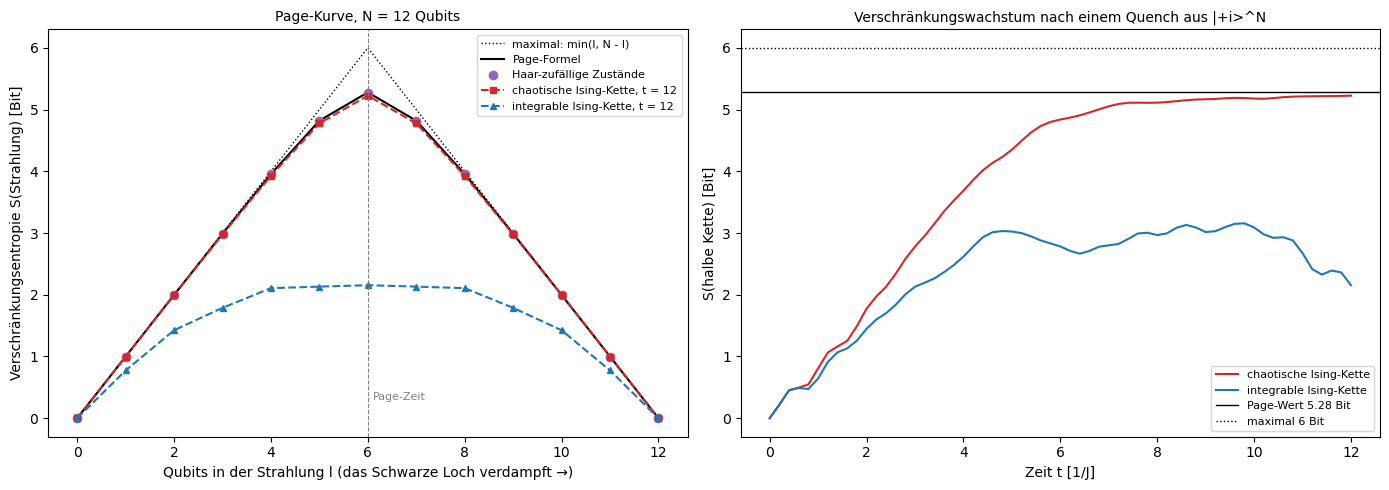

Page-Kurve (N = 12)
  Page-Wert bei l = N/2:          5.279 Bit  (≈ N/2 - 1/(2 ln 2) = 5.279)
  Haar-zufällige Zustände:        5.274 Bit
  Chaotische Kette, späte Zeiten: 5.135 Bit  (Zeitmittel für t > 6)
  Integrable Kette, späte Zeiten: 2.841 Bit


In [6]:
from scipy import sparse
from scipy.sparse.linalg import expm_multiply

def ising_hamiltonian_sparse(n, h_x, h_z, J=1.0):
    """Derselbe Hamiltonoperator wie ising_hamiltonian, als dünne Matrix (nötig für n > 10)."""
    def op(o, j):
        return sparse.kron(sparse.kron(sparse.identity(2 ** j), sparse.csr_matrix(o)), sparse.identity(2 ** (n - j - 1)), format="csr")
    H = sum(J * op(Z, i) @ op(Z, i + 1) for i in range(n - 1))
    return H + sum(h_x * op(X, i) + h_z * op(Z, i) for i in range(n))

def entanglement_entropy(psi, l, n):
    """Von-Neumann-Entropie (in Bit) der ersten l Qubits eines reinen Zustands aus n Qubits."""
    if l in (0, n):
        return 0.0
    s = np.linalg.svd(psi.reshape(2 ** l, 2 ** (n - l)), compute_uv=False)
    p = s[s > 1e-12] ** 2
    return float(-(p * np.log2(p)).sum())

def page_entropy(l, n):
    """Page (1993): mittlere Entropie eines Teilsystems der Dimension m <= k in einem Haar-zufälligen Zustand auf m*k (in Bit)."""
    m, k = sorted([2 ** l, 2 ** (n - l)])
    return (sum(1 / j for j in range(k + 1, m * k + 1)) - (m - 1) / (2 * k)) / np.log(2)

# --- Ausführung ---
N_PAGE = 12
ells = np.arange(N_PAGE + 1)
rng = np.random.default_rng(7)

# (a) Page-Kurve: Haar-zufällige Zustände gegen die Page-Formel und die einfache Schranke min(l, n - l)
haar_states = [(lambda v: v / np.linalg.norm(v))(rng.normal(size=2 ** N_PAGE) + 1j * rng.normal(size=2 ** N_PAGE)) for _ in range(5)]
S_haar = np.array([[entanglement_entropy(psi, l, N_PAGE) for l in ells] for psi in haar_states]).mean(axis=0)
S_page = np.array([page_entropy(l, N_PAGE) for l in ells])

# (b) Dynamik: Entropie der halben Kette nach einem Quench aus dem Produktzustand |+i>^N
#     (<H> = 0 für diesen Zustand, also unendliche Temperatur; |00...0> liegt am Rand des Spektrums und verschränkt wenig)
page_times = np.linspace(0, 12, 61)
plus_i = np.array([1, 1j]) / np.sqrt(2)
psi_init = plus_i
for _ in range(N_PAGE - 1):
    psi_init = np.kron(psi_init, plus_i)
S_t = {}
for label, hz in [("chaotisch", H_Z), ("integrabel", 0.0)]:
    H_sp = ising_hamiltonian_sparse(N_PAGE, H_X, hz)
    states = expm_multiply(-1j * H_sp, psi_init, start=page_times[0], stop=page_times[-1], num=len(page_times), endpoint=True)
    S_t[label] = np.array([entanglement_entropy(psi, N_PAGE // 2, N_PAGE) for psi in states])
    S_t[label + "_kurve"] = np.array([entanglement_entropy(states[-1], l, N_PAGE) for l in ells])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(ells, np.minimum(ells, N_PAGE - ells), "k:", lw=1, label="maximal: min(l, N - l)")
axes[0].plot(ells, S_page, "k-", lw=1.5, label="Page-Formel")
axes[0].plot(ells, S_haar, "o", c="tab:purple", label="Haar-zufällige Zustände")
axes[0].plot(ells, S_t["chaotisch_kurve"], "s--", c="tab:red", ms=5, label=f"chaotische Ising-Kette, t = {page_times[-1]:.0f}")
axes[0].plot(ells, S_t["integrabel_kurve"], "^--", c="tab:blue", ms=5, label=f"integrable Ising-Kette, t = {page_times[-1]:.0f}")
axes[0].axvline(N_PAGE / 2, color="grey", lw=0.8, ls="--")
axes[0].text(N_PAGE / 2 + 0.1, 0.3, "Page-Zeit", color="grey", fontsize=8)
axes[0].set_xlabel("Qubits in der Strahlung l (das Schwarze Loch verdampft →)")
axes[0].set_ylabel("Verschränkungsentropie S(Strahlung) [Bit]")
axes[0].set_title(f"Page-Kurve, N = {N_PAGE} Qubits", fontsize=10)
axes[0].legend(fontsize=8)

axes[1].plot(page_times, S_t["chaotisch"], c="tab:red", label="chaotische Ising-Kette")
axes[1].plot(page_times, S_t["integrabel"], c="tab:blue", label="integrable Ising-Kette")
axes[1].axhline(page_entropy(N_PAGE // 2, N_PAGE), color="black", ls="-", lw=1, label=f"Page-Wert {page_entropy(N_PAGE // 2, N_PAGE):.2f} Bit")
axes[1].axhline(N_PAGE / 2, color="black", ls=":", lw=1, label=f"maximal {N_PAGE // 2} Bit")
axes[1].set_xlabel("Zeit t [1/J]")
axes[1].set_ylabel(f"S(halbe Kette) [Bit]")
axes[1].set_title("Verschränkungswachstum nach einem Quench aus |+i>^N", fontsize=10)
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

late = page_times > page_times[-1] / 2
print(f"Page-Kurve (N = {N_PAGE})")
print(f"  Page-Wert bei l = N/2:          {S_page[N_PAGE // 2]:.3f} Bit  (≈ N/2 - 1/(2 ln 2) = {N_PAGE / 2 - 1 / (2 * np.log(2)):.3f})")
print(f"  Haar-zufällige Zustände:        {S_haar[N_PAGE // 2]:.3f} Bit")
print(f"  Chaotische Kette, späte Zeiten: {S_t['chaotisch'][late].mean():.3f} Bit  (Zeitmittel für t > {page_times[-1] / 2:.0f})")
print(f"  Integrable Kette, späte Zeiten: {S_t['integrabel'][late].mean():.3f} Bit")

* Das **linke Bild** zeigt die Entropie der ersten $l$ Qubits gegen $l$. Die gepunktete Linie ist das Maximum $\min(l, N - l)$, die schwarze Linie die Page-Formel, die in der Mitte unter dem Maximum bleibt. Die Haar-zufälligen Zustände (lila) liegen auf der Page-Kurve, ebenso die chaotische Kette bei $t = 12$ (rot): Ihr Zustand sieht aus wie ein Zufallszustand. Die integrable Kette (blau) bleibt weit darunter, in der Mitte bei etwa 2.1 Bit.
* Das **rechte Bild** zeigt die Entropie der halben Kette über der Zeit. Beide Ketten beginnen mit einem linearen Anstieg, dem Wachstum $S \approx v_Et$ aus Theorie, Abschnitt 5. Die chaotische Kette steigt bis $t \approx 7$ weiter und bleibt dann knapp unter dem Page-Wert; die integrable bleibt bei etwa 3 Bit stehen und schwankt zwischen 2.2 und 3.2 Bit.
* Die **Ausgabe** gibt den Page-Wert $5.279$ Bit $= 6 - 1/(2\ln2)$ und $5.274$ Bit für die Haar-zufälligen Zustände. Die chaotische Kette erreicht nach $t = 6$ im Mittel $5.135$ Bit, nahe am Page-Wert. Die integrable Kette hat im Mittel $2.841$ Bit: Die Kette freier Fermionen thermalisiert nicht zu einem Zufallszustand, sondern relaxiert auf ein verallgemeinertes Gibbs-Ensemble mit kleinerer Entropie.

##### *5. Zeitskalen: Heisenberg-Zeit und Poincaré-Wiederkehr*

Wie lange braucht die Kette, um zu ihrem Anfangszustand zurückzukehren, und wie verhält sich das zu den anderen Zeitskalen? Vorher vorhersagen: Um wie viele Größenordnungen wächst die Wiederkehrzeit, wenn die Kette ein Qubit länger wird?

Der Anfangszustand ist $\vert{+i}\rangle^{\otimes N}$ aus Experiment 4. Für $N = 1$ bis 12 berechnet die Zelle seine Gewichte $p_n$ auf den Energieniveaus, die Heisenberg-Zeit $t_H$ und die Abschätzung der mittleren Zeit bis zur Rückkehr zu $P > 0.9$ (Theorie, Abschnitt 13). Für $N \le 4$ sucht sie die Rückkehren außerdem direkt, bis $t = 2\cdot10^6$, für die chaotische und die integrable Kette (etwa eine Minute). **Links:** der größte und der mittlere Wert von $P(t)$ in logarithmischen Zeitfenstern für 3 und 8 Qubits. **Mitte:** die kurzen Zeitskalen gegen $N$. **Rechts:** $\log_{10}$ der Wiederkehrzeit gegen $N$, mit dem Alter des Universums für eine Kopplung $J/2\pi = 10$ MHz, wie bei supraleitenden Qubits.

**Hintergrund & Fachbegriffe:**
- **Rückkehrwahrscheinlichkeit:** $P(t) = \vert\langle\psi(0)\vert\psi(t)\rangle\vert^2$; 1 bei $t = 0$ und nahe einer Wiederkehr.
- **Effektive Zahl der Niveaus:** $D_\text{eff} = 1/\sum p_n^2$, wie viele Eigenzustände der Anfangszustand wirklich besetzt; das Zeitmittel von $P$ ist $1/D_\text{eff}$.
- **Heisenberg-Zeit:** $2\pi$ geteilt durch den Niveauabstand, die Zeit, nach der die Dynamik einzelne Niveaus auflöst.
- **Lemma von Kac:** Für eine Bewegung, die alle ihre möglichen Zustände gleichmäßig besucht, ist die mittlere Zeit bis zur Rückkehr in einen Bereich die Verweildauer pro Besuch geteilt durch den Zeitanteil, den sie dort verbringt.

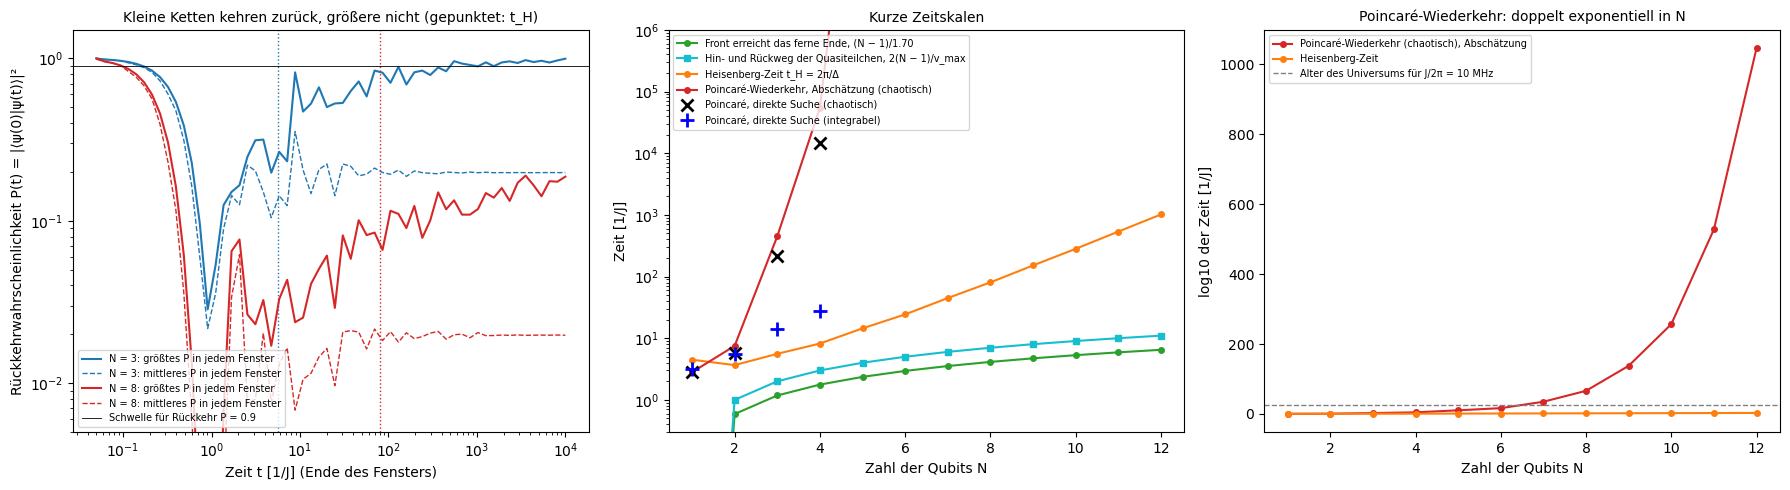

(56 s)
 N  Niveaus  D_eff     t_H    log10 t_P (Abschätzung)
 1        2     2.0      4.5        0.4
 2        3     2.7      3.7        0.9
 3        6     5.0      5.6        2.7
 4       10     6.1      8.2        4.7
 5       20    11.1     14.4       10.5
 6       36    15.0     24.3       16.7
 7       72    25.8     44.8       35.1
 8      136    50.6     80.5       66.3
 9      272   101.1    151.3      137.8
10      528   157.7    281.4      256.9
11     1056   346.3    535.5      528.3
12     2080   654.9   1015.0     1046.6
Mittlere Zeit zwischen Rückkehren zu P > 0.9, direkte Suche:
  N = 1: chaotisch      2.81 (Abschätzung      2.81),  integrabel      3.14   (gesucht bis t = 2e+02)
  N = 2: chaotisch      5.79 (Abschätzung      7.51),  integrabel      5.55   (gesucht bis t = 2e+03)
  N = 3: chaotisch       212 (Abschätzung       449),  integrabel      14.2   (gesucht bis t = 2e+05)
  N = 4: chaotisch  1.44e+04 (Abschätzung  5.44e+04),  integrabel      27.8   (gesucht bis t

In [7]:
import time
from scipy.special import gammaln

def survival_weights(n, h_z):
    """Energien E_n und Gewichte p_n = |<n|psi0>|^2 der Niveaus, die psi0 = |+i>^N berührt (Theorie, Abschnitt 13)."""
    E, U = np.linalg.eigh(ising_hamiltonian_sparse(n, H_X, h_z).toarray().real)
    psi = plus_i
    for _ in range(n - 1):
        psi = np.kron(psi, plus_i)
    p = np.abs(U.T @ psi) ** 2
    keep = p > 1e-12
    return E[keep], p[keep]

def survival(E, p, t):
    """Rückkehrwahrscheinlichkeit P(t) = |<psi0|psi(t)>|^2 = |Σ_n p_n e^{-i E_n t}|^2."""
    return np.abs(np.exp(-1j * np.outer(t, E)) @ p) ** 2

def heisenberg_time(E):
    """t_H = 2π/Δ, mit dem Niveauabstand Δ in der Mitte eines ungefähr gaußförmigen Spektrums: t_H = √(2π) n / σ_E."""
    return np.sqrt(2 * np.pi) * len(E) / E.std()

def recurrence_estimate(E, p, eps=0.1):
    """log10 der mittleren Zeit zwischen Rückkehren zu P > 1 - eps (Lemma von Kac, Phasen E_n t als unabhängig behandelt)."""
    k = len(p) - 1
    log_fraction = (k / 2) * np.log(np.pi / (2 * np.pi) ** 2 * eps) - gammaln(k / 2 + 1) - 0.5 * np.sum(np.log(p))
    dwell = 2 * np.sqrt(eps) / np.sqrt(p @ E ** 2 - (p @ E) ** 2)
    return (np.log(dwell) - log_fraction) / np.log(10)

def recurrence_scan(E, p, T, eps=0.1, dt=0.02, chunk=1_000_000):
    """Direkte Suche bis zur Zeit T: mittlerer Abstand zwischen aufeinanderfolgenden Rückkehren zu P > 1 - eps (nach dem ersten Abfall)."""
    entries, last_above = [], True                        # P(0) = 1: Start oberhalb der Schwelle
    for start in np.arange(0, T, chunk * dt):
        t = start + dt * np.arange(chunk)
        above = survival(E, p, t) > 1 - eps
        rising = np.flatnonzero(above & ~np.r_[last_above, above[:-1]])
        entries.extend(t[rising])
        last_above = above[-1]
    return np.diff(np.r_[0.0, entries]).mean() if len(entries) > 1 else np.nan

# --- Ausführung ---
t0 = time.time()
NS = np.arange(1, 13)
levels = {n: survival_weights(n, H_Z) for n in NS}
t_H = np.array([heisenberg_time(levels[n][0]) for n in NS])
log_tP = np.array([recurrence_estimate(*levels[n]) for n in NS])
SCAN_T = {1: 200, 2: 2000, 3: 2e5, 4: 2e6}
scan_chaos = {n: recurrence_scan(*levels[n], SCAN_T[n]) for n in SCAN_T}
scan_int = {n: recurrence_scan(*survival_weights(n, 0.0), SCAN_T[n]) for n in SCAN_T}
v_front = front_speed(C_chaos)[0]
AGE = np.log10(4.35e17 * 2 * np.pi * 1e7)        # Alter des Universums in Einheiten von 1/J für J/2π = 10 MHz

def window_max(E, p, t_max=1e4, dt=0.02, n_bins=60):
    """Größter und mittlerer Wert von P(t) in logarithmischen Zeitfenstern bis t_max (stückweise berechnet, um Speicher zu sparen)."""
    edges = np.r_[0, np.geomspace(0.05, t_max, n_bins)]
    big, mean = np.zeros(n_bins), np.zeros(n_bins)
    for i in range(n_bins):
        t = np.arange(edges[i], edges[i + 1], dt)
        vals = np.concatenate([survival(E, p, t[k:k + 200_000]) for k in range(0, len(t), 200_000)])
        big[i], mean[i] = vals.max(), vals.mean()
    return edges[1:], big, mean

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for n, c in [(3, "tab:blue"), (8, "tab:red")]:
    E, p = levels[n]
    t_end, big, mean = window_max(E, p)
    axes[0].semilogx(t_end, big, "-", c=c, lw=1.5, label=f"N = {n}: größtes P in jedem Fenster")
    axes[0].semilogx(t_end, mean, "--", c=c, lw=1, label=f"N = {n}: mittleres P in jedem Fenster")
    axes[0].axvline(heisenberg_time(E), color=c, ls=":", lw=1)
axes[0].axhline(0.9, color="black", ls="-", lw=0.6, label="Schwelle für Rückkehr P = 0.9")
axes[0].set_yscale("log")
axes[0].set_ylim(5e-3, 1.5)
axes[0].set_xlabel("Zeit t [1/J] (Ende des Fensters)")
axes[0].set_ylabel("Rückkehrwahrscheinlichkeit P(t) = |⟨ψ(0)|ψ(t)⟩|²")
axes[0].set_title("Kleine Ketten kehren zurück, größere nicht (gepunktet: t_H)", fontsize=10)
axes[0].legend(fontsize=7, loc="lower left")

axes[1].semilogy(NS, (NS - 1 + 1e-9) / v_front, "o-", c="tab:green", ms=4, label=f"Front erreicht das ferne Ende, (N − 1)/{v_front:.2f}")
axes[1].semilogy(NS, (NS - 1 + 1e-9), "s-", c="tab:cyan", ms=4, label="Hin- und Rückweg der Quasiteilchen, 2(N − 1)/v_max")
axes[1].semilogy(NS, t_H, "o-", c="tab:orange", ms=4, label="Heisenberg-Zeit t_H = 2π/Δ")
axes[1].semilogy(NS[:5], 10 ** log_tP[:5], "o-", c="tab:red", ms=4, label="Poincaré-Wiederkehr, Abschätzung (chaotisch)")
axes[1].semilogy(list(scan_chaos), list(scan_chaos.values()), "kx", ms=8, mew=2, label="Poincaré, direkte Suche (chaotisch)")
axes[1].semilogy(list(scan_int), list(scan_int.values()), "b+", ms=10, mew=2, label="Poincaré, direkte Suche (integrabel)")
axes[1].set_ylim(0.3, 1e6)
axes[1].set_xlabel("Zahl der Qubits N")
axes[1].set_ylabel("Zeit [1/J]")
axes[1].set_title("Kurze Zeitskalen", fontsize=10)
axes[1].legend(fontsize=7, loc="upper left")

axes[2].plot(NS, log_tP, "o-", c="tab:red", ms=4, label="Poincaré-Wiederkehr (chaotisch), Abschätzung")
axes[2].plot(NS, np.log10(t_H), "o-", c="tab:orange", ms=4, label="Heisenberg-Zeit")
axes[2].axhline(AGE, color="grey", ls="--", lw=1, label="Alter des Universums für J/2π = 10 MHz")
axes[2].set_xlabel("Zahl der Qubits N")
axes[2].set_ylabel("log10 der Zeit [1/J]")
axes[2].set_title("Poincaré-Wiederkehr: doppelt exponentiell in N", fontsize=10)
axes[2].legend(fontsize=7, loc="upper left")
plt.tight_layout()
plt.show()

print(f"({time.time() - t0:.0f} s)")
print(" N  Niveaus  D_eff     t_H    log10 t_P (Abschätzung)")
for i, n in enumerate(NS):
    E, p = levels[n]
    print(f"{n:2d}  {len(p):7d}  {1 / np.sum(p ** 2):6.1f}  {t_H[i]:7.1f}   {log_tP[i]:8.1f}")
print("Mittlere Zeit zwischen Rückkehren zu P > 0.9, direkte Suche:")
for n in SCAN_T:
    print(f"  N = {n}: chaotisch {scan_chaos[n]:9.3g} (Abschätzung {10 ** log_tP[n - 1]:9.3g}),  integrabel {scan_int[n]:9.3g}   (gesucht bis t = {SCAN_T[n]:.0e})")

* Das **linke Bild** zeigt die Rückkehrwahrscheinlichkeit auf logarithmischer Zeitachse. Beide Ketten zerfallen bis $t \approx 1$. Bei 3 Qubits (blau) pendelt sich das Mittel (gestrichelt) nach der Heisenberg-Zeit 5.6 (gepunktet) bei $1/D_\text{eff} = 0.20$ ein, und der größte Wert in jedem Fenster steigt ab $t \approx 500$ wieder über 0.9: Der Zustand kehrt immer wieder zurück. Bei 8 Qubits (rot) pendelt sich das Mittel nach $t_H = 80$ bei 0.020 ein, und selbst der größte Wert bleibt bis $t = 10^4$ unter 0.2: keine Rückkehr in Sicht.
* Das **mittlere Bild** ordnet die kurzen Zeitskalen. Die Front durchquert die Kette in $(N - 1)/1.70$ Zeiteinheiten, die Quasiteilchen der integrablen Kette brauchen $N - 1$ für Hin- und Rückweg (die zurückkehrenden Fronten aus Experiment 1), beide linear in $N$. Die Heisenberg-Zeit liegt über beiden und wächst exponentiell, von 4.5 auf 1015. Bei einem oder zwei Qubits kommt eine Wiederkehr etwa so bald wie die Heisenberg-Zeit (eine einzige Periode); ab drei Qubits schießen die direkt gesuchten Wiederkehrzeiten der chaotischen Kette (schwarze Kreuze) nach oben, 212 bei 3 Qubits und 14 400 bei 4, während die der integrablen Kette (blau) langsam wachsen, 14 und 28: Sie hat nur $N$ unabhängige Frequenzen.
* Das **rechte Bild** zeigt die Abschätzung auf einer Skala von $\log_{10}$ der Zeit: etwa $10^{17}$ bei 6 Qubits, $10^{35}$ bei 7, also länger als das Alter des Universums ($10^{25.4}$ Zeiteinheiten), und $10^{1047}$ bei 12. Die **Ausgabe** vergleicht die Abschätzung mit der direkten Suche: 2.81 gegen 2.81 bei $N = 1$ und um den Faktor 1.3 bis 3.8 zu groß bei $N = 2$ bis 4, weil $\varepsilon = 0.1$ nicht sehr klein ist. Auf dieser Skala ist das unsichtbar: Die Wiederkehrzeit ist doppelt exponentiell in $N$, die Heisenberg-Zeit nur exponentiell.

#### **Ergebnis**

Beim Lauf vom 2026-10-24:

- **Lichtkegel (Experiment 1):** In der Mixed-Field-Ising-Kette mit 8 Qubits läuft die OTOC-Front in beiden Phasen ballistisch und erreicht das ferne Ende bei $t = 3.9$ (integrabel) und $4.1$ (chaotisch), mit 1.83 und 1.70 Plätzen pro Zeiteinheit, knapp unter dem schnellsten Quasiteilchen, $v_\text{max} = 2$. Der Unterschied liegt hinter der Front: Die integrable Kette relaxiert gegen $C = 0$ (spätes Mittel am fernen Ende 0.27), und ihre Front wird an den offenen Enden reflektiert und kehrt bei $t = 13.4$ und $22.0$ zurück; die chaotische Kette sättigt nahe dem gescrambelten Wert (0.94). Die Lösung mit freien Fermionen gibt das exakte integrable Ergebnis bis auf $3\cdot10^{-13}$ wieder und zeigt dasselbe Zickzack für 24 Qubits.
- **Schmetterlingsgeschwindigkeit (Experiment 2):** $v_B = 0.595$ Plätze pro Schicht in zufälligen Ziegelstein-Schaltkreisen (12 Qubits, 20 Schaltkreise) gegen exakt $(q^2-1)/(q^2+1) = 0.600$; mit 14 Qubits und 20 Schichten 0.594.
- **Hayden-Preskill (Experiment 3):** Der maximale Clifford-Scrambler gibt $P = 0.250$, $F = 1.000$; Haar-zufällige 3-Qubit-Matrizen $F = 0.58 \pm 0.04$; die chaotische Ising-Kette bis $F = 0.81$ und bleibt gescrambelt, die integrable erreicht $0.82$ und entscrambelt sich wieder (bis $0.28$). Depolarisierendes Rauschen senkt $P$ auf 0.25 wie ein Scrambler, aber $F$ bleibt bei 1/4. $F\,d_A^2P = 1$ gilt für alle unitären Scrambler bis auf $3\cdot10^{-15}$.
- **Page-Kurve (Experiment 4):** Page-Wert bei $l = N/2$ 5.279 Bit, Haar-zufällige Zustände 5.274 Bit. Nach einem Quench aus $\vert{+i}\rangle^{\otimes 12}$ erreicht die chaotische Kette 5.14 Bit, nahe am Page-Wert, und ihre späte Page-Kurve liegt auf der Kurve der Zufallszustände; die integrable Kette bleibt bei etwa 2.8 Bit (verallgemeinertes Gibbs-Ensemble).
- **Zeitskalen (Experiment 5):** Die Heisenberg-Zeit von $\vert{+i}\rangle^{\otimes N}$ wächst von 4.5 ($N = 1$) auf 80 ($N = 8$) und 1015 ($N = 12$). Die mittlere Zeit zwischen Rückkehren zu $P > 0.9$ ist 2.8, 5.8, 212 und 14 400 für $N = 1$ bis 4 in der chaotischen Kette, aber nur 3.1, 5.6, 14 und 28 in der integrablen. Die Abschätzung wächst doppelt exponentiell: $10^{17}$ bei 6 Qubits, $10^{35}$ bei 7 (länger als das Alter des Universums bei $J/2\pi = 10$ MHz), $10^{1047}$ bei 12.

#### **Variationen**

Jeweils zuerst die Vorhersage notieren, dann den Code ändern und prüfen:

1. **Schmetterling in der Mitte:** In Experiment 1 $V = X_{N/2}$ nehmen (`site_op(X, n // 2, n)`). Für die Version mit freien Fermionen die Zeilen $N$ und $N+1$ von $e^{-At}$ statt der ersten beiden. *(Vorhersage: Zwei Fronten laufen in der halben Zeit zu beiden Enden; in der integrablen Kette werden sie reflektiert und kreuzen sich in der Mitte.)*
2. **Schwaches Chaos:** `H_Z = 0.1`. *(Vorhersage: Die Front bleibt ballistisch, und die zurückkehrenden Fronten sind am fernen Ende noch zu sehen; aber zwischen ihnen fällt $C$ nicht mehr auf 0, sondern driftet zum gescrambelten Wert, mit einem späten Mittel von etwa 0.8 statt 0.27.)*
3. **Weg vom kritischen Punkt:** `H_X = 0.5`. *(Vorhersage: $v_\text{max} = 2\min(J, h_x) = 1$; die Front braucht etwa doppelt so lange und erreicht $j = 6$ erst bei $t \approx 7$. Das letzte Qubit reagiert kaum: Für $h_x < J$ ist die Kette in ihrer geordneten Phase, in der $Z$ auf dem End-Qubit fast erhalten ist, eine Majorana-Randmode.)*
4. **Größere Zufallsschaltkreise:** In Experiment 2 `N_RC = 14` und `DEPTH = 20` (etwa 1.5 Minuten). *(Vorhersage: $v_B$ bleibt nahe 0.6; der Lauf vom 2026-10-24 gab 0.594.)*
5. **Scrambling plus Rauschen:** In Experiment 3 `decode(U_MAX, p)` für $p = 0.05$ und $0.2$. *(Vorhersage: $P$ bleibt bei 1/4, aber $F$ fällt auf etwa 0.95 und 0.80; $F\,d_A^2P$ ist nicht mehr 1, weil die Entwicklung nicht unitär ist.)*
6. **Quench vom Rand des Spektrums:** In Experiment 4 mit $\vert 0\dots0\rangle$ statt $\vert{+i}\rangle^{\otimes N}$ starten. *(Vorhersage: Dieser Zustand hat die Energie $\langle H\rangle = (N-1)J + Nh_z = 17$, nahe am oberen Rand des Spektrums bei 19.7 und weit weg von unendlicher Temperatur; selbst die chaotische Kette bleibt deshalb bei etwa 1 Bit statt 5.28.)*
7. **Strengere Rückkehr:** In Experiment 5 `recurrence_estimate(*levels[n], eps=0.01)`. *(Vorhersage: Die Abschätzung wächst um etwa $D/2 - 1$ Größenordnungen, mit der Zahl $D$ der Niveaus: Der Zeitanteil schrumpft um $10^{-(D-1)/2}$, die Verweildauer um $10^{-1/2}$; also 2 Größenordnungen bei 3 Qubits (6 Niveaus), 4 bei 4 Qubits (10 Niveaus).)*
8. **Ein Qubit mehr in der direkten Suche:** `SCAN_T[5] = 2e6` (einige Minuten). *(Vorhersage: Die integrable Kette kehrt im Mittel alle 230 Zeiteinheiten zurück, die chaotische kein einziges Mal, passend zur Abschätzung von $10^{10.5}$.)*

#### **Wiederholung**

Erst selbst antworten, dann aufklappen.

<details><summary>1. Warum lässt sich die klassische Definition von Chaos nicht auf die Quantenmechanik übertragen, und was tritt an ihre Stelle?</summary>

Klassisches Chaos ist das exponentielle Auseinanderlaufen benachbarter Bahnen. Die Quantenmechanik hat keine Bahnen, und die unitäre Entwicklung hält den Überlapp zweier Zustände konstant. Stattdessen betrachtet man, wie Operatoren wachsen (OTOCs), die Statistik der Energieniveaus (Niveauabstoßung wie bei Zufallsmatrizen) und die Eigenzustände (ETH).
</details>

<details><summary>2. Was misst der OTOC, und was bedeuten die Werte C = 0, C = 1 und C = 2?</summary>

Er misst, wie stark $W(t)$ nicht mehr mit $V$ vertauscht: $C = 1 - \mathrm{Re}\,F$ ist der halbe quadrierte Kommutator. $C = 0$: Sie vertauschen noch, die Störung ist nicht angekommen. $C = 1$ ($F = 0$): $W(t)$ ist vollständig gescrambelt. $C = 2$: Sie antivertauschen, wie $Z_0$ und $X_0$ bei $t = 0$.
</details>

<details><summary>3. Warum heißt er „out of time order“, und wie misst man ihn?</summary>

Die Zeiten in $F(t) = \langle W(t)VW(t)V\rangle$ laufen $t \to 0 \to t \to 0$; man kann ihn nicht mit einem einzigen vorwärts laufenden Zeitweg schreiben. Gemessen wird er als Echo: vorwärts entwickeln, $V$ anwenden, rückwärts entwickeln und mit $W$ vergleichen. Alles, was mit $V$ vertauscht, hebt sich auf; nur der nicht vertauschende Teil bleibt.
</details>

<details><summary>4. Warum ist die Ising-Kette ohne Längsfeld „frei“, und was bringt das?</summary>

Die Jordan-Wigner-Transformation macht $H$ quadratisch in Majorana-Fermionen; jeder Majorana-Operator entwickelt sich linear mit einer $2N\times2N$-Matrix $e^{At}$. Der OTOC wird zu einer $2\times2$-Determinante, und 24 Qubits dauern weniger als eine Sekunde statt einer Rechnung in $2^{24}$ Dimensionen.
</details>

<details><summary>5. Beide Ketten breiten sich ballistisch aus. Was unterscheidet sie hinter der Front?</summary>

In der integrablen Kette laufen die Quasiteilchen durch: $C$ fällt wieder gegen 0 (spätes Mittel 0.27 am fernen Ende), und die Front kehrt nach jeder Reflexion zurück. In der chaotischen Kette sättigt $C$ nahe dem gescrambelten Wert 1 (0.94) und bleibt dort.
</details>

<details><summary>6. Woher kommt das Zickzack- oder W-Muster in der integrablen Kette?</summary>

Von Quasiteilchen, die sich ballistisch bewegen, höchstens mit $v_\text{max} = 2\min(J, h_x)$, und an den offenen Enden reflektiert werden. Hin- und Rückweg dauern etwa $2(N-1)/v_\text{max}$. Es ist keine Poincaré-Wiederkehr, die unvorstellbar viel länger dauert; in der chaotischen Kette streuen die Quasiteilchen, und keine Front kommt zurück.
</details>

<details><summary>7. Was begrenzt die Geschwindigkeit der Front, und wie hängen v_LR, v_B und v_max zusammen?</summary>

Die Lieb-Robinson-Schranke: Außerhalb des Kegels $d > v_\text{LR}t$ ist jeder Kommutator exponentiell klein, also $v_B \le v_\text{LR}$. In der freien Kette läuft die Front mit dem schnellsten Quasiteilchen, $v_\text{max} = 2$; die Durchgänge durch die halbe Höhe laufen mit 1.83 (integrabel) und 1.70 Plätzen pro Zeiteinheit (chaotisch).
</details>

<details><summary>8. Warum ist v_B = 3/5 in Zufallsschaltkreisen aus Qubits, und warum wird die Front breiter?</summary>

Nach dem Mitteln über Haar-zufällige Gatter macht das rechte Ende des Operators eine Zufallsbewegung mit Vorwärtstendenz; daraus folgt $v_B = (q^2-1)/(q^2+1) = 3/5$ für $q = 2$ in Einheiten des strengen Lichtkegels. Eine Zufallsbewegung breitet sich diffusiv aus, deshalb wird die Front wie $\sqrt t$ breiter.
</details>

<details><summary>9. Was zeigen P_EPR und F_EPR des Yoshida-Kitaev-Dekoders für einen perfekten Scrambler und ohne Scrambling?</summary>

Perfekter Scrambler: $P = 1/d_A^2 = 1/4$ und $F = 1$, das Tagebuch kommt perfekt an. Ohne Scrambling: $P = 1$ und $F = 1/4$, nichts wird zurückgewonnen. Für unitäres $U$ gilt immer $F = 1/(d_A^2P)$.
</details>

<details><summary>10. Wie unterscheidet man Scrambling von Dekohärenz?</summary>

Beide lassen den OTOC zerfallen. Nur Scrambling erhöht die Dekodier-Fidelity: Mit depolarisierendem Rauschen fällt $P$ auf 1/4 wie bei einem perfekten Scrambler, aber $F$ bleibt bei 1/4. Das Rauschen hat die Information zerstört, statt sie in Korrelationen zu verstecken.
</details>

<details><summary>11. Was ist die Page-Kurve, und warum liegt der Wert bei N/2 unter N/2 Bit?</summary>

Die Verschränkungsentropie der Strahlung gegen die Zahl der abgestrahlten Qubits: Sie steigt um etwa ein Bit pro Qubit bis zur Page-Zeit $l = N/2$ und fällt danach. Selbst ein Zufallszustand ist über die Mitte nicht maximal verschränkt; Pages Formel gibt ein Defizit von $1/(2\ln2) \approx 0.72$ Bit, 5.28 statt 6 Bit bei 12 Qubits.
</details>

<details><summary>12. Warum bleibt die integrable Kette nach einem Quench weit unter dem Page-Wert?</summary>

Sie hat viele Erhaltungsgrößen, die Besetzungen aller Quasiteilchen-Moden, und relaxiert auf ein verallgemeinertes Gibbs-Ensemble statt auf einen Zufallszustand. Ihre Verschränkung sättigt bei etwa 2.8 Bit statt 5.28.
</details>

<details><summary>13. Was ist die Scrambling-Zeit, und warum gelten Schwarze Löcher als schnellste Scrambler?</summary>

$t_\ast \sim \lambda_L^{-1}\ln N$, die Zeit, nach der sich eine lokale Störung über das ganze System verteilt hat. Die MSS-Schranke begrenzt $\lambda_L \le 2\pi k_BT/\hbar$; Schwarze Löcher und das SYK-Modell erreichen sie, ihre Scrambling-Zeit $\sim\frac{\beta}{2\pi}\ln S$ ist also die kürzest mögliche.
</details>

<details><summary>14. Welche statischen Signaturen unterscheiden chaotische von integrablen Spektren?</summary>

Das Verhältnis aufeinanderfolgender Niveauabstände, $\langle r\rangle \approx 0.53$ für chaotische (GOE) und $\approx 0.39$ für integrable Spektren (Poisson), und die Form Abfall, Rampe, Plateau des spektralen Formfaktors, deren Rampe von der Niveauabstoßung kommt.
</details>

<details><summary>15. Was heißt „ballistisch“, und was ist in einer chaotischen Kette diffusiv?</summary>

Ballistisch: Ein Abstand wächst wie $vt$, mit konstanter Geschwindigkeit; doppelte Zeit, doppelter Weg. Diffusiv: Er wächst wie $\sqrt t$, wie bei einer Zufallsbewegung; doppelter Weg braucht die vierfache Zeit. Die OTOC-Front läuft in beiden Ketten ballistisch; in der chaotischen Kette sind die Breite der Front und der Transport der Energie diffusiv.
</details>

<details><summary>16. Ist jeder wachsende OTOC ein Zeichen für Scrambling?</summary>

Nein. Auch in der integrablen Kette breitet sich die Front ballistisch aus, aber der Operator bleibt einfach (eine Bilinearform aus Fermionen), $C$ fällt hinter der Front wieder gegen 0, und die Information reist mit den Quasiteilchen. Scrambling heißt, dass $C$ hinter der Front sättigt und die Information aus keinem kleinen Teil mehr zurückzugewinnen ist.
</details>

<details><summary>17. Was ist die Heisenberg-Zeit, und was ändert sich danach?</summary>

$t_H = 2\pi\hbar/\Delta$ mit dem mittleren Niveauabstand $\Delta$; sie wächst wie $2^N/N$. Davor sieht das Spektrum kontinuierlich aus, und Relaxation und Scrambling finden statt. Danach löst die Dynamik einzelne Niveaus auf: Der spektrale Formfaktor erreicht sein Plateau, und Schwankungen mitteln sich nicht weiter heraus.
</details>

<details><summary>18. Warum dauert eine Poincaré-Wiederkehr doppelt exponentiell lange, und wann spielt sie eine Rolle?</summary>

Eine Rückkehr verlangt, dass alle Phasen $E_nt$ gleichzeitig zusammenpassen; der Zeitanteil mit $P > 1 - \varepsilon$ fällt wie $\varepsilon^{D/2}$ mit $D \sim 2^N$ Niveaus. Sie spielt eine Rolle bei Systemen mit wenigen Niveaus (Rabi-Oszillationen, Jaynes-Cummings-Wiederaufleben) und kommt viel früher in integrablen Systemen mit nur $N$ unabhängigen Frequenzen; in chaotischen Vielteilchensystemen spielt sie praktisch nie eine Rolle.
</details>

#### **Nächste Schritte**

- **Spektralstatistik derselben Kette:** Niveauabstoßung, Symmetriesektoren und spektraler Formfaktor in [Spektralstatistik und Quantenchaos](https://github.com/deltorobarba/science/blob/main/quantum/chaos_spectra.ipynb).
- **Eigenzustands-Thermalisierung:** Diagonal- und Nichtdiagonalelemente in [Eigenzustands-Thermalisierung](https://github.com/deltorobarba/science/blob/main/quantum/chaos_eth.ipynb).
- **Krylov-Komplexität:** Lanczos-Koeffizienten und Krylov-Kette in [Krylov-Komplexität](https://github.com/deltorobarba/science/blob/main/quantum/chaos_krylov.ipynb).
- **Unordnung:** Zufällige Felder $h_i$ bremsen die Front; bei starker Unordnung breitet sich die OTOC-Front nur noch logarithmisch aus, siehe [Vielteilchenlokalisierung](https://github.com/deltorobarba/science/blob/main/quantum/chaos_mbl.ipynb).
- **Längere Ketten:** das Operatorwachstum mit Matrixprodukt-Operatoren (TEBD) für 50 bis 100 Qubits verfolgen, wo sich Form und Verbreiterung der Front über lange Strecken messen lassen.
- **Rauschen:** Dephasierung (eine Lindblad-Gleichung) zu Experiment 1 hinzufügen und sehen, wie Rauschen Scrambling vortäuscht, dann mit dem Dekoder-Test aus Experiment 3 prüfen.

#### **Referenzen**

- Poincaré, H. (1890): *Sur le problème des trois corps et les équations de la dynamique*, Acta Math. 13, 1 (Wiederkehrsatz).
- Kac, M. (1947): *On the notion of recurrence in discrete stochastic processes*, Bull. Amer. Math. Soc. 53, 1002 (Lemma von Kac).
- Bocchieri, P. & Loinger, A. (1957): *Quantum recurrence theorem*, Phys. Rev. 107, 337.
- Larkin, A. I. & Ovchinnikov, Yu. N. (1969): *Quasiclassical method in the theory of superconductivity*, Sov. Phys. JETP 28, 1200.
- Pfeuty, P. (1970): *The one-dimensional Ising model with a transverse field*, Ann. Phys. 57, 79 (Lösung mit freien Fermionen).
- Lieb, E. H. & Robinson, D. W. (1972): *The finite group velocity of quantum spin systems*, Commun. Math. Phys. 28, 251.
- Eberly, J. H., Narozhny, N. B. & Sanchez-Mondragon, J. J. (1980): *Periodic spontaneous collapse and revival in a simple quantum model*, Phys. Rev. Lett. 44, 1323.
- Bohigas, O., Giannoni, M. J. & Schmit, C. (1984): *Characterization of chaotic quantum spectra and universality of level fluctuation laws*, Phys. Rev. Lett. 52, 1.
- Page, D. N. (1993): *Average entropy of a subsystem*, Phys. Rev. Lett. 71, 1291.
- Hayden, P. & Preskill, J. (2007): *Black holes as mirrors: quantum information in random subsystems*, JHEP 09, 120.
- Sekino, Y. & Susskind, L. (2008): *Fast scramblers*, JHEP 10, 065.
- Kim, H. & Huse, D. A. (2013): *Ballistic spreading of entanglement in a diffusive nonintegrable system*, Phys. Rev. Lett. 111, 127205.
- Maldacena, J., Shenker, S. H. & Stanford, D. (2016): *A bound on chaos*, JHEP 08, 106.
- D'Alessio, L., Kafri, Y., Polkovnikov, A. & Rigol, M. (2016): *From quantum chaos and eigenstate thermalization to statistical mechanics and thermodynamics*, Adv. Phys. 65, 239.
- Mezei, M. & Stanford, D. (2017): *On entanglement spreading in chaotic systems*, JHEP 05, 065.
- Yoshida, B. & Kitaev, A. (2017): *Efficient decoding for the Hayden–Preskill protocol*, arXiv:1710.03363.
- Nahum, A., Vijay, S. & Haah, J. (2018): *Operator spreading in random unitary circuits*, Phys. Rev. X 8, 021014.
- von Keyserlingk, C. W., Rakovszky, T., Pollmann, F. & Sondhi, S. L. (2018): *Operator hydrodynamics, OTOCs, and entanglement growth in systems without conservation laws*, Phys. Rev. X 8, 021013.
- Lin, C.-J. & Motrunich, O. I. (2018): *Out-of-time-ordered correlators in a quantum Ising chain*, Phys. Rev. B 97, 144304.
- Boixo, S. et al. (2018): *Characterizing quantum supremacy in near-term devices*, Nat. Phys. 14, 595.
- McClean, J. R. et al. (2018): *Barren plateaus in quantum neural network training landscapes*, Nat. Commun. 9, 4812.
- Yoshida, B. & Yao, N. Y. (2019): *Disentangling scrambling and decoherence via quantum teleportation*, Phys. Rev. X 9, 011006.
- Landsman, K. A. et al. (2019): *Verified quantum information scrambling*, Nature 567, 61.
- Parker, D. E., Cao, X., Avdoshkin, A., Scaffidi, T. & Altman, E. (2019): *A universal operator growth hypothesis*, Phys. Rev. X 9, 041017.
- Dalzell, A. M., Hunter-Jones, N. & Brandão, F. G. S. L. (2022): *Random quantum circuits anticoncentrate in log depth*, PRX Quantum 3, 010333.